# AI Agents for Automation - AI-powered Last-Mile Delivery Exception Handling

**Anoop Krishnan** | Post Graduate Program in AI & ML: Business Applications, McCombs School of Business, The University of Texas at Austin | Full-Code Path | October 2026

A LangGraph multi-agent proof of concept that ingests noisy delivery logs, de-duplicates and consolidates events, retrieves policy from the operations playbook (RAG), decides and validates a resolution, escalates to a supervisor when policy requires it, drafts tier-appropriate customer notifications, and evaluates itself on task completion, escalation accuracy, tool-call accuracy, reasoning coherence and latency.

---

# **Problem Statement**

## Business Context

In last-mile logistics, roughly 10% of all shipments encounter delivery exceptions - failed attempts, address mismatches, damaged packages, refused deliveries, and weather delays. Each failed delivery costs in direct reattempt expenses, while the downstream impact is far steeper: consumers stop shopping with a retailer after just 2-3 failed deliveries, and supply chain disruptions cost companies millions per year.

Despite these costs, most organizations still handle exception triage and resolution manually. Operations staff read through status logs and messy driver notes, cross-reference customer profiles and internal playbooks, decide on a resolution action, and draft customer notifications - all under time pressure. Teams rely on support tickets, tribal knowledge, and rigid rule engines that cannot handle the nuanced, multi-factor judgment calls that real exceptions demand. A VIP customer with a perishable package and a broken gate code on a second attempt requires a fundamentally different resolution than a standard customer's first failed attempt on a non-perishable item - but manual processes treat them with the same slow, inconsistent workflow.

Key KPIs affected include:
- Exception resolution time (constrained by manual triage throughput)
- Escalation accuracy (missed or unnecessary supervisor escalations)
- Customer communication quality and personalization
- Cost per exception (reattempt costs, spoilage write-offs, unnecessary truck rolls)
- Customer retention and lifetime value

If unaddressed, logistics providers face rising exception-handling costs, inconsistent service quality, preventable customer churn, and loss of competitive ground to players who are already investing in AI-powered exception detection and response automation.

By applying an AI-powered multi-agent system that ingests delivery logs, cross-references customer profiles and locker availability, retrieves resolution policy from an operational playbook, and generates validated decisions with personalized customer communications, logistics providers can automate the full exception-handling pipeline from detection through resolution, with built-in quality validation and supervisor escalation where policy requires it.


## Objective

The objective is to build a POC of an AI-powered multi-agent delivery exception handling system for the last-mile delivery operations of a mid-sized retailer that:
- uses the operator's available data to process exceptions end-to-end,
- ingests raw delivery status logs, including noisy, duplicated, and multi-row shipment events, and correctly identifies actionable exceptions versus routine operational noise,
- decides the appropriate resolution action (reschedule, reroute to locker, replace, or return to sender) by reasoning over playbook rules, customer context, package constraints, and locker eligibility, while respecting operational policies around perishable handling, fragile thresholds, and locker capacity.
- escalates to a human supervisor when policy requires it and avoids unnecessary escalations that waste supervisor capacity,
- generates personalized customer notifications with tone, channel, and content calibrated to customer tier and exception severity, and
- produces auditable decisions with step-by-step rationale, critical validation traces, and system evaluation metrics across five dimensions: task completion rate, escalation accuracy, tool call accuracy, reasoning trajectory coherence, and end-to-end latency.

The end goal is to demonstrate measurable accuracy and consistency on curated exception scenarios sufficient to justify scaling the approach to real-time operations with live delivery feeds, broader exception taxonomies, and multi-region deployment.


## Data Dictionary

The data comprises three types of files.

### SQLite Database (`customers.db`)

**Table: `customers`** - 12 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| customer_id | string | Primary key (`CUST-001` to `CUST-012`), Foreign key in delivery logs |
| name | string | Customer full name (**PII**) |
| tier | string | STANDARD, PREMIUM, VIP |
| preferred_channel | string | SMS, EMAIL |
| exceptions_last_90d | integer | Range: 0-6 |
| active_credit | float | Range: \$0.00-\$20.00 |

**Table: `lockers`** - 6 records

| Attribute | Type | Values / Description |
|:---|:---|:---|
| locker_id | string | Primary key (`LOC-001` to `LOC-006`) |
| address | string | Locker street address |
| zip_code | string | 10001-10006 |
| capacity_status | string | AVAILABLE, LIMITED, FULL |
| operating_hours | string | e.g., "6AM-10PM" or "24 hours" |
| max_package_size | string | SMALL, MEDIUM, LARGE |

### CSV Files

**Delivery Status Logs (`delivery_logs.csv`)** - 13 rows, 10 unique shipments

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | `SHP-001` to `SHP-010`. Multiple rows may share the same ID for multi-event shipments. |
| timestamp | datetime | ISO format |
| status_code | string | One of seven codes: DELIVERED, ATTEMPTED, DAMAGED, ADDRESS_ISSUE, REFUSED, WEATHER_DELAY, SCANNED |
| status_description | string | Free-text driver/handler notes |
| customer_id | string | Foreign key to `customers` table (`CUST-001` to `CUST-012`) |
| delivery_address | string | Full address including zip code |
| package_type | string | STANDARD, PERISHABLE, FRAGILE |
| package_size | string | SMALL, MEDIUM, LARGE |
| attempt_number | integer | 0 for pre-delivery scans, 1+ for delivery attempts |
| is_duplicate_scan | boolean | True for repeated scan events |

**Ground Truth Labels (`ground_truth.csv`)** - 13 rows, aligned 1:1 with delivery logs

| Attribute | Type | Values / Description |
|:---|:---|:---|
| shipment_id | string | Matches delivery logs (`SHP-001` to `SHP-010`) |
| is_exception | string | YES, NO |
| expected_resolution | string | RESCHEDULE, REPLACE, REROUTE_TO_LOCKER, RETURN_TO_SENDER, N/A |
| expected_tone | string | FORMAL, CASUAL, N/A |
| should_escalate | string | YES, NO, N/A |
| ground_truth_reasoning | string | Step-by-step justification tracing each label to specific playbook rules, customer attributes, and locker constraints |

### Exception Resolution Playbook (`exception_resolution_playbook.pdf`)

An internal operations manual for human dispatchers in natural language.

# **Installing and Importing Necessary Libraries and Dependencies**

In [1]:
# Install the pinned dependencies when they are not already present (fresh Colab runtime).
# If every required package can be imported, nothing is installed and a note is printed instead.
import importlib.util, subprocess, sys

PINNED = [
    "langchain==1.2.10", "langchain-openai==1.1.10", "langgraph==1.0.8", "langsmith==0.7.3",
    "langchain-community==0.4.1", "langchain-huggingface==1.2.0", "openai==2.21.0",
    "pandas==2.2.2", "numpy==2.0.2", "scikit-learn==1.6.1", "sentence-transformers==5.2.3",
    "pydantic==2.12.3", "langchain-chroma", "langchain-text-splitters", "pypdf",
]
REQUIRED_MODULES = ["langchain", "langchain_openai", "langgraph", "langsmith", "langchain_community",
                    "langchain_chroma", "langchain_text_splitters", "pypdf", "pandas", "numpy", "pydantic", "openai"]

missing = [m for m in REQUIRED_MODULES if importlib.util.find_spec(m) is None]
if missing:
    print(f"Installing pinned dependencies (missing: {missing}) ...")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *PINNED], check=False)
    print("Install finished - restart the kernel/runtime once, then run all cells from the next cell onward.")
else:
    print("All required packages are already installed - skipping pip install.")


All required packages are already installed - skipping pip install.


**Note:** versions are pinned to the ones the project template was validated with. After a fresh install the kernel/runtime must be restarted once before the remaining cells are run.

In [2]:
import warnings                                                                 # Silence noisy library warnings (set first so import-time warnings are hidden)
warnings.filterwarnings("ignore")

# --- Standard library ---
import os                                                                       # Environment variables and file paths
import re                                                                       # Regex for text normalisation and parsing
import csv                                                                      # Reading the delivery log CSV inside a tool
import json                                                                     # Config loading and structured logging
import time                                                                     # End-to-end latency measurement
import sqlite3                                                                  # Customer / locker database access
from collections import defaultdict                                             # Grouping rows per shipment
from typing import TypedDict, Literal, Optional                                 # Typed agent state and output schemas

# --- Data handling and plotting ---
import pandas as pd                                                             # Tabular data
import numpy as np                                                              # Numeric helpers
import matplotlib.pyplot as plt                                                 # Evaluation charts

# --- Structured outputs ---
from pydantic import BaseModel, Field, model_validator                          # Agent output schemas with validation

# --- LangChain core building blocks ---
from langchain_core.tools import tool                                           # @tool decorator for agent tools
from langchain_core.messages import SystemMessage, HumanMessage                 # Chat message types
from langchain_core.callbacks import BaseCallbackHandler                        # Custom observability callback
from langchain_openai import ChatOpenAI                                         # OpenAI chat models

# --- RAG: document loading, chunking, embeddings, vector store ---
from langchain_community.document_loaders import PyPDFLoader                    # PDF -> LangChain Documents
from langchain_text_splitters import RecursiveCharacterTextSplitter             # Chunking
from langchain_openai import OpenAIEmbeddings                                   # Embeddings for the playbook vector store
from langchain_chroma import Chroma                                             # ChromaDB vector store

# --- LangGraph: multi-agent workflow ---
from langgraph.graph import StateGraph, START, END                              # Graph definition primitives

# --- LangSmith tracing ---
from langsmith import traceable                                                 # Decorator that traces nodes when tracing is on

# --- Notebook display helpers ---
from IPython.display import Image, display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

# Keep every figure the same pixel width in the exported HTML (Colab otherwise crops each figure to content)
try:
    get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
except Exception:
    pass

print("Libraries imported successfully.")


Libraries imported successfully.


# **LLM and Agent Observability Setup**

We load the OpenAI and (optional) LangSmith credentials from a `config.json` file that sits next to the notebook and store them as environment variables. The file is **never** printed and is not part of the submission.

Expected format (only `OPENAI_API_KEY` is mandatory):

```json
{
  "OPENAI_API_KEY": "sk-...",
  "OPENAI_API_BASE": "",
  "LANGCHAIN_TRACING_V2": "false",
  "LANGCHAIN_API_KEY": "",
  "LANGCHAIN_PROJECT": "delivery-exception-agents"
}
```

- If `OPENAI_API_BASE` is empty, the official OpenAI endpoint is used.
- If a LangSmith key is supplied, every node decorated with `@traceable` is traced in the LangSmith project; otherwise the decorator is a no-op and we rely on the in-notebook trajectory/tool logs for observability.

In [3]:
# Load the JSON file and extract values
file_name = 'config.json'                                                       # Name of the configuration file
with open(file_name, 'r') as file:                                              # Open the config file in read mode
    config = json.load(file)                                                    # Load the JSON content as a dictionary

OPENAI_API_KEY = config.get("OPENAI_API_KEY")                                   # Extract OpenAI API key (mandatory)
OPENAI_API_BASE = config.get("OPENAI_API_BASE")                                 # Extract OpenAI base URL (optional)

LANGCHAIN_TRACING_V2 = str(config.get("LANGCHAIN_TRACING_V2", "false")).lower() # Extract LangSmith tracing flag
LANGCHAIN_API_KEY = config.get("LANGCHAIN_API_KEY")                             # Extract LangSmith API key (optional)
LANGCHAIN_PROJECT = config.get("LANGCHAIN_PROJECT", "delivery-exception-agents")# Extract LangSmith project name

assert OPENAI_API_KEY, "OPENAI_API_KEY is missing from config.json"

# Store OpenAI credentials in environment variables
os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY                                   # Set OpenAI API key
if OPENAI_API_BASE:                                                             # Only override the base URL when one is given
    os.environ['OPENAI_BASE_URL'] = OPENAI_API_BASE

# Store LangSmith credentials in environment variables (tracing only when a key is present)
if LANGCHAIN_API_KEY and LANGCHAIN_TRACING_V2 == "true":
    os.environ['LANGCHAIN_TRACING_V2'] = "true"                                 # Enable LangSmith tracing
    os.environ['LANGCHAIN_API_KEY'] = LANGCHAIN_API_KEY                         # Set LangSmith API key
    os.environ['LANGCHAIN_PROJECT'] = LANGCHAIN_PROJECT                         # Set LangSmith project
    print(f"LangSmith tracing ENABLED -> project '{LANGCHAIN_PROJECT}'")
else:
    os.environ['LANGCHAIN_TRACING_V2'] = "false"
    print("LangSmith tracing disabled - using in-notebook trajectory and tool-call logs for observability")

print(f"OpenAI key loaded ({len(OPENAI_API_KEY)} characters) | base URL: {OPENAI_API_BASE or 'default (api.openai.com)'}")


LangSmith tracing disabled - using in-notebook trajectory and tool-call logs for observability
OpenAI key loaded (164 characters) | base URL: default (api.openai.com)


We use two models with distinct responsibilities, both at `temperature=0` so decisions are reproducible:

| Handle | Model | Used by | Why |
|:--|:--|:--|:--|
| `gen_llm` | `gpt-4o-mini` | Resolution Agent, Communication Agent | Fast and inexpensive; the heavy lifting (rules, retrieval, escalation engine) is done by tools, so the generator mainly needs reliable structured output. |
| `eval_llm` | `gpt-4o` | Critic Agent (both validation nodes) and the LLM-as-a-Judge coherence scorer | A stronger model as the quality gate gives an independent check on the cheaper generator. |

A lightweight callback handler is attached to both models to count LLM invocations and tokens per test case - this is our in-notebook observability layer alongside the trajectory log.

In [4]:
class LLMCallTracker(BaseCallbackHandler):
    """Counts LLM calls and tokens so each test case can report its own LLM usage."""
    def __init__(self):
        self.reset()

    def reset(self):
        self.calls = 0
        self.prompt_tokens = 0
        self.completion_tokens = 0

    def on_llm_end(self, response, **kwargs):
        self.calls += 1
        try:
            # Token usage travels on the AIMessage as usage_metadata (langchain-openai >= 0.2)
            for generation_list in response.generations:
                for gen in generation_list:
                    usage = getattr(getattr(gen, "message", None), "usage_metadata", None) or {}
                    self.prompt_tokens += usage.get("input_tokens", 0)
                    self.completion_tokens += usage.get("output_tokens", 0)
        except Exception:
            pass                                                                # Never let observability break the pipeline

    def snapshot(self) -> dict:
        return {"llm_calls": self.calls,
                "prompt_tokens": self.prompt_tokens,
                "completion_tokens": self.completion_tokens}


llm_tracker = LLMCallTracker()

GEN_MODEL = "gpt-4o-mini"                                                       # Generator for resolution + communication
EVAL_MODEL = "gpt-4o"                                                           # Critic + LLM-as-a-Judge

gen_llm = ChatOpenAI(model=GEN_MODEL, temperature=0, max_retries=3, callbacks=[llm_tracker])
eval_llm = ChatOpenAI(model=EVAL_MODEL, temperature=0, max_retries=3, callbacks=[llm_tracker])

# Smoke test - confirms the key, endpoint and both models are reachable before we build anything on top
for name, llm in [("gen_llm", gen_llm), ("eval_llm", eval_llm)]:
    reply = llm.invoke([HumanMessage(content="Reply with exactly three words: model is ready")])
    print(f"{name:8s} ({llm.model_name}): {reply.content.strip()}")

print("\nLLM usage so far:", llm_tracker.snapshot())
llm_tracker.reset()


gen_llm  (gpt-4o-mini): Model is ready.


eval_llm (gpt-4o): Model is ready.

LLM usage so far: {'llm_calls': 2, 'prompt_tokens': 32, 'completion_tokens': 8}


# **Data Loading and Vector Database Setup**

## Locating the data files

The four data files are expected either next to the notebook or inside a `Datasets Last-Mile Delivery` sub-folder (the structure of the project zip). On Colab, upload them to `/content` or unzip the dataset there.

In [5]:
CANDIDATE_DIRS = [
    ".",                                                                        # Files next to the notebook
    "Datasets Last-Mile Delivery",                                              # Unzipped project folder
    "/content", "/content/Datasets Last-Mile Delivery",                         # Colab defaults
    "/content/drive/MyDrive/Datasets Last-Mile Delivery",                       # Google Drive mount
]
DATA_DIR = next((d for d in CANDIDATE_DIRS if os.path.exists(os.path.join(d, "customers.db"))), None)
assert DATA_DIR is not None, "customers.db not found - upload the four data files first"

CUSTOMERS_DB_PATH = os.path.join(DATA_DIR, "customers.db")
DELIVERY_LOGS_PATH = os.path.join(DATA_DIR, "delivery_logs.csv")
GROUND_TRUTH_PATH = os.path.join(DATA_DIR, "ground_truth.csv")
PLAYBOOK_PDF_PATH = os.path.join(DATA_DIR, "exception_resolution_playbook.pdf")

for p in [CUSTOMERS_DB_PATH, DELIVERY_LOGS_PATH, GROUND_TRUTH_PATH, PLAYBOOK_PDF_PATH]:
    print(f"{'OK ' if os.path.exists(p) else 'MISSING'}  {p}  ({os.path.getsize(p) if os.path.exists(p) else 0:,} bytes)")


OK   ./customers.db  (20,480 bytes)
OK   ./delivery_logs.csv  (2,303 bytes)
OK   ./ground_truth.csv  (2,372 bytes)
OK   ./exception_resolution_playbook.pdf  (126,396 bytes)


## Loading the CSV files

In [6]:
# Raw delivery event stream - the input to the multi-agent system
delivery_logs_df = pd.read_csv(DELIVERY_LOGS_PATH)

# Evaluation targets - one label row per delivery log row
ground_truth_df = pd.read_csv(GROUND_TRUTH_PATH, keep_default_na=False)      # keep "N/A" as a label, not NaN

print(f"delivery_logs.csv : {delivery_logs_df.shape[0]} rows x {delivery_logs_df.shape[1]} columns")
print(f"ground_truth.csv  : {ground_truth_df.shape[0]} rows x {ground_truth_df.shape[1]} columns")

print("\n--- Delivery logs ---")
display(delivery_logs_df)

print("\n--- Ground truth ---")
display(ground_truth_df)


delivery_logs.csv : 13 rows x 10 columns
ground_truth.csv  : 13 rows x 6 columns

--- Delivery logs ---


,shipment_id,timestamp,status_code,status_description,customer_id,delivery_address,package_type,package_size,attempt_number,is_duplicate_scan
0,SHP-001,2026-03-05T10:14:00,DELIVERED,"Left at front door, signed by resident",CUST-003,"27 Maple Drive, Greenfield, 10001",STANDARD,SMALL,1,False
1,SHP-002,2026-03-05T11:05:00,ATTEMPTED,Nobody home rang bell twice no answer left notice on door,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,False
2,SHP-002,2026-03-05T11:07:00,ATTEMPTED,Nobody home rang bell twice no answer left notice on door,CUST-001,"140 Birch Lane, Westdale, 10003",STANDARD,MEDIUM,1,True
3,SHP-003,2026-03-05T09:45:00,ADDRESS_ISSUE,cant find building 999 on this street asked around nobody knows it,CUST-005,"999 Oak Avenue, Riverside, 10002",STANDARD,SMALL,1,False
4,SHP-004,2026-03-05T08:30:00,DAMAGED,Box crushed on one side contents might be damaged visible dent,CUST-008,"12 Pine Road, Northgate, 10004",FRAGILE,LARGE,1,False
5,SHP-005,2026-03-05T13:15:00,ATTEMPTED,3rd try customer still not available building has no buzzer system,CUST-011,"88 Elm Boulevard, Westdale, 10003",STANDARD,MEDIUM,3,False
6,SHP-006,2026-03-05T10:50:00,REFUSED,Customer opened door said they didnt order this refused to accept,CUST-007,"301 Main Street, Greenfield, 10001",STANDARD,SMALL,1,False
7,SHP-007,2026-03-05T14:00:00,WEATHER_DELAY,Heavy snow on route roads blocked estimated 5hr delay,CUST-004,"78 Birch Court, Southfield, 10006",PERISHABLE,MEDIUM,1,False
8,SHP-007,2026-03-05T14:03:00,WEATHER_DELAY,Heavy snow on route roads blocked estimated 5hr delay,CUST-004,"78 Birch Court, Southfield, 10006",PERISHABLE,MEDIUM,1,True
9,SHP-008,2026-03-05T13:45:00,ATTEMPTED,Went to address again customer not in neighbor said they work late,CUST-011,"88 Elm Boulevard, Westdale, 10003",STANDARD,SMALL,2,False



--- Ground truth ---


,shipment_id,is_exception,expected_resolution,expected_tone,should_escalate,ground_truth_reasoning
0,SHP-001,NO,N/A,N/A,N/A,Successful delivery. Monitoring agent should filter this as noise.
1,SHP-002,YES,RESCHEDULE,FORMAL,YES,1st failed attempt for VIP customer with 5 exceptions in 90d (>=3 threshold). Playbook...
2,SHP-002,NO,N/A,N/A,N/A,Duplicate scan of row 1. Monitoring agent should deduplicate and discard.
3,SHP-003,YES,RESCHEDULE,CASUAL,NO,"Address not found. Standard customer, no prior exceptions. Contact customer to verify ..."
4,SHP-004,YES,REPLACE,FORMAL,YES,Damaged fragile package for VIP customer. Playbook lowers damage threshold for fragile...
5,SHP-005,YES,REROUTE_TO_LOCKER,CASUAL,YES,3rd failed attempt — automatic escalation. Locker LOC-003 in zip 10003 is FULL. System...
6,SHP-006,YES,RETURN_TO_SENDER,CASUAL,NO,"Customer refused delivery, said they didn't order it. Playbook: return to sender. Stan..."
7,SHP-007,YES,REPLACE,FORMAL,YES,"Perishable with 5hr weather delay exceeds 4hr threshold. Playbook: pull from route, in..."
8,SHP-007,NO,N/A,N/A,N/A,Duplicate scan of SHP-007 weather delay. Monitoring agent should deduplicate and discard.
9,SHP-008,YES,RESCHEDULE,CASUAL,YES,2nd attempt. STANDARD customer with 6 exceptions in 90d (>5 discretionary escalation t...


A quick profile of the event stream tells us what the preprocessor has to cope with: repeated scans, shipments that span several rows, and routine (non-exception) status codes mixed in with real exceptions.

Rows: 13 | Unique shipments: 10 | Duplicate scans flagged: 2
Multi-row shipments: {'SHP-002': np.int64(3), 'SHP-007': np.int64(2)}

Ground truth: 9 exception rows, 4 noise/duplicate rows


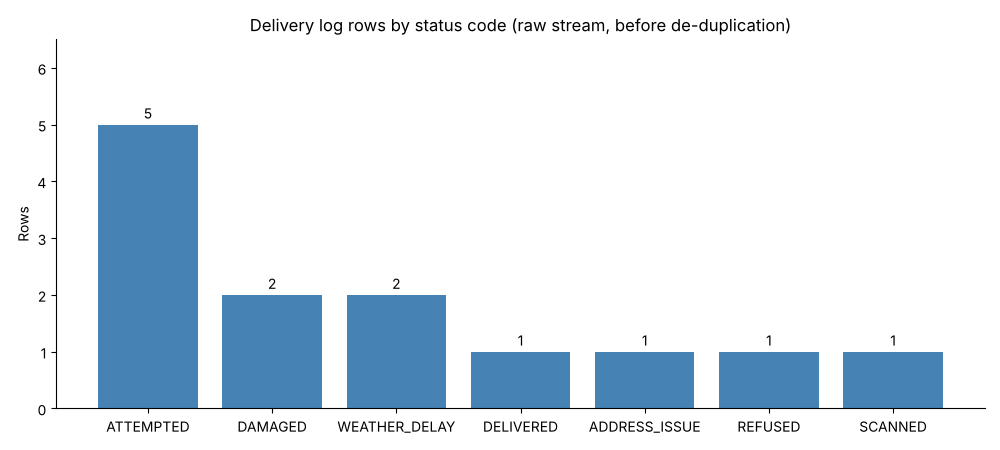

,raw_rows,duplicate_scans,max_attempt,status_codes
shipment_id,,,,
SHP-001,1,0,1,DELIVERED
SHP-002,3,1,2,ATTEMPTED
SHP-003,1,0,1,ADDRESS_ISSUE
SHP-004,1,0,1,DAMAGED
SHP-005,1,0,3,ATTEMPTED
SHP-006,1,0,1,REFUSED
SHP-007,2,1,1,WEATHER_DELAY
SHP-008,1,0,2,ATTEMPTED
SHP-009,1,0,1,DAMAGED


In [7]:
# How noisy is the stream?
n_rows = len(delivery_logs_df)
n_shipments = delivery_logs_df["shipment_id"].nunique()
n_dupes = int((delivery_logs_df["is_duplicate_scan"].astype(str).str.lower() == "true").sum())
multi_row = delivery_logs_df["shipment_id"].value_counts()
multi_row = multi_row[multi_row > 1]

print(f"Rows: {n_rows} | Unique shipments: {n_shipments} | Duplicate scans flagged: {n_dupes}")
print(f"Multi-row shipments: {dict(multi_row)}")
print(f"\nGround truth: {int((ground_truth_df['is_exception']=='YES').sum())} exception rows, "
      f"{int((ground_truth_df['is_exception']=='NO').sum())} noise/duplicate rows")

# Status code mix
status_counts = delivery_logs_df["status_code"].value_counts()
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(status_counts.index, status_counts.values, color="#4682B4")
ax.bar_label(bars, padding=2)
ax.set_title("Delivery log rows by status code (raw stream, before de-duplication)")
ax.set_ylabel("Rows")
ax.set_ylim(0, status_counts.max() + 1.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Shipment-level view: raw rows vs rows after removing duplicate scans
rows_per_shipment = delivery_logs_df.groupby("shipment_id").agg(
    raw_rows=("shipment_id", "size"),
    duplicate_scans=("is_duplicate_scan", lambda s: int((s.astype(str).str.lower() == "true").sum())),
    max_attempt=("attempt_number", "max"),
    status_codes=("status_code", lambda s: ", ".join(dict.fromkeys(s)))
)
display(rows_per_shipment)


## Loading the SQLite database

In [8]:
# Connect to the SQLite database and inspect the schema
conn = sqlite3.connect(CUSTOMERS_DB_PATH)

schema_df = pd.read_sql("SELECT name, sql FROM sqlite_master WHERE type='table'", conn)
for _, r in schema_df.iterrows():
    print(f"TABLE {r['name']}:\n  {r['sql']}\n")

# Load both tables into DataFrames for inspection
customers_df = pd.read_sql("SELECT * FROM customers", conn)
lockers_df = pd.read_sql("SELECT * FROM lockers", conn)
conn.close()                                                                    # Tools open their own connection later

print(f"customers: {customers_df.shape[0]} rows | lockers: {lockers_df.shape[0]} rows\n")
print("--- customers (name is PII - shown here only for data understanding) ---")
display(customers_df)
print("\n--- lockers ---")
display(lockers_df)

# Context that drives several test cases: tier distribution and exception history
print("\nCustomers by tier:", customers_df["tier"].value_counts().to_dict())
print("Customers with >=3 exceptions in 90d:",
      customers_df.loc[customers_df["exceptions_last_90d"] >= 3, ["customer_id", "tier", "exceptions_last_90d"]].to_dict("records"))
print("Lockers that are FULL:", lockers_df.loc[lockers_df["capacity_status"] == "FULL", "locker_id"].tolist())


TABLE customers:
  CREATE TABLE customers (customer_id TEXT PRIMARY KEY, name TEXT NOT NULL, tier TEXT NOT NULL CHECK(tier IN ('STANDARD','PREMIUM','VIP')), preferred_channel TEXT NOT NULL CHECK(preferred_channel IN ('SMS','EMAIL')), exceptions_last_90d INTEGER NOT NULL DEFAULT 0, active_credit REAL NOT NULL DEFAULT 0.0)

TABLE lockers:
  CREATE TABLE lockers (locker_id TEXT PRIMARY KEY, address TEXT NOT NULL, zip_code TEXT NOT NULL, capacity_status TEXT NOT NULL CHECK(capacity_status IN ('AVAILABLE','LIMITED','FULL')), operating_hours TEXT NOT NULL, max_package_size TEXT NOT NULL CHECK(max_package_size IN ('SMALL','MEDIUM','LARGE')))

customers: 12 rows | lockers: 6 rows

--- customers (name is PII - shown here only for data understanding) ---


,customer_id,name,tier,preferred_channel,exceptions_last_90d,active_credit
0,CUST-001,John Smith,VIP,EMAIL,5,15.0
1,CUST-002,Jane Doe,PREMIUM,EMAIL,2,0.0
2,CUST-003,Robert Johnson,STANDARD,SMS,0,0.0
3,CUST-004,Maria Garcia,VIP,EMAIL,1,10.0
4,CUST-005,David Wilson,STANDARD,SMS,0,0.0
5,CUST-006,Sarah Brown,PREMIUM,EMAIL,3,5.0
6,CUST-007,Michael Lee,STANDARD,SMS,1,0.0
7,CUST-008,Emily Davis,VIP,EMAIL,4,20.0
8,CUST-009,James Taylor,STANDARD,SMS,0,0.0
9,CUST-010,Lisa Anderson,PREMIUM,EMAIL,2,0.0



--- lockers ---


,locker_id,address,zip_code,capacity_status,operating_hours,max_package_size
0,LOC-001,"150 Main Street, Greenfield",10001,AVAILABLE,6AM-10PM,LARGE
1,LOC-002,"42 Oak Avenue, Riverside",10002,LIMITED,7AM-9PM,MEDIUM
2,LOC-003,"88 Elm Boulevard, Westdale",10003,FULL,24 hours,LARGE
3,LOC-004,"215 Pine Road, Northgate",10004,AVAILABLE,8AM-8PM,SMALL
4,LOC-005,"33 Cedar Lane, Eastport",10005,LIMITED,6AM-11PM,MEDIUM
5,LOC-006,"170 Birch Court, Southfield",10006,AVAILABLE,24 hours,LARGE



Customers by tier: {'STANDARD': 5, 'PREMIUM': 4, 'VIP': 3}
Customers with >=3 exceptions in 90d: [{'customer_id': 'CUST-001', 'tier': 'VIP', 'exceptions_last_90d': 5}, {'customer_id': 'CUST-006', 'tier': 'PREMIUM', 'exceptions_last_90d': 3}, {'customer_id': 'CUST-008', 'tier': 'VIP', 'exceptions_last_90d': 4}, {'customer_id': 'CUST-011', 'tier': 'STANDARD', 'exceptions_last_90d': 6}]
Lockers that are FULL: ['LOC-003']


## Loading the PDF file

`PyPDFLoader` returns one `Document` per page. This particular PDF is extracted by `pypdf` with **one word per line**, which would wreck both chunking and embedding quality, so we normalise all whitespace to single spaces. We also convert the page index to a human-friendly 1-based page number, which the agents later cite as `[Page N]`.

In [9]:
# Load the playbook - one Document per page
loader = PyPDFLoader(PLAYBOOK_PDF_PATH)
playbook_pages = loader.load()

# Normalise whitespace (pypdf emits one word per line for this PDF) and use 1-based page numbers for citations
for i, doc in enumerate(playbook_pages):
    doc.page_content = re.sub(r"\s+", " ", doc.page_content).strip()
    doc.metadata["page"] = i + 1
    doc.metadata["source"] = "exception_resolution_playbook.pdf"

print(f"Loaded {len(playbook_pages)} pages | total characters: {sum(len(d.page_content) for d in playbook_pages):,}\n")
for doc in playbook_pages:
    preview = doc.page_content[:110].replace("\n", " ")
    print(f"[Page {doc.metadata['page']:2d}] {len(doc.page_content):5,} chars | {preview}...")


Loaded 10 pages | total characters: 15,281

[Page  1] 1,168 chars | Last-Mile Delivery Operations Exception Resolution Playbook Internal Use Only - Operations Team Document Versi...
[Page  2] 2,136 chars | 1. Failed Delivery Attempts This is the most common exception you’ll deal with. The driver went to the address...
[Page  3] 1,644 chars | 2. Address Mismatches Address issues come in a few ﬂavors. The building number doesn’t exist, the street name ...
[Page  4] 1,713 chars | 3. Damaged Packages When a package is ﬂagged as damaged, we need to make a judgment call: is it safe to delive...
[Page  5] 1,351 chars | 4. Refused Deliveries Sometimes the customer is home but doesn’t want the package. This could be because they ...
[Page  6] 1,882 chars | 5. Weather Delays Bad weather is outside our control, but how we communicate about it is not. When weather eve...
[Page  7] 1,911 chars | 6. Locker Reroute Procedures Rerouting a package to a nearby pickup locker is one of the best tools we h

## Creating Vector Database

We chunk the pages with a `RecursiveCharacterTextSplitter` (700 characters, 120 overlap) so that each chunk holds one coherent rule block (e.g. "Third Attempt", "Perishable Packages - CRITICAL") and still carries its page number. Chunks are embedded with OpenAI's `text-embedding-3-small` (the whole playbook is about 30 chunks, a fraction of a cent) and stored in **ChromaDB**; a local sentence-transformer such as `all-MiniLM-L6-v2` via `langchain_huggingface` is a drop-in alternative when no embedding API is available. Fixed chunk IDs make the cell idempotent - re-running it upserts instead of duplicating.

In [10]:
# Chunk the pages - page metadata is inherited by every chunk
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=700,
    chunk_overlap=120,
    separators=["\n\n", "\n", ". ", " ", ""]
)
playbook_chunks = text_splitter.split_documents(playbook_pages)
print(f"{len(playbook_pages)} pages -> {len(playbook_chunks)} chunks "
      f"(avg {np.mean([len(c.page_content) for c in playbook_chunks]):.0f} chars)")

# Embedding model for the playbook chunks
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small", check_embedding_ctx_length=False)  # chunks are short; skip tiktoken pre-tokenisation

# Build the ChromaDB vector store with deterministic IDs (idempotent)
chunk_ids = [f"playbook-chunk-{i:03d}" for i in range(len(playbook_chunks))]
playbook_vectorstore = Chroma.from_documents(
    documents=playbook_chunks,
    embedding=embedding_model,
    ids=chunk_ids,
    collection_name="exception_resolution_playbook"
)
playbook_retriever = playbook_vectorstore.as_retriever(search_kwargs={"k": 4})
print(f"Vector store ready: {playbook_vectorstore._collection.count()} chunks indexed\n")

# Retrieval sanity check - each query should land on the matching playbook section
sanity_queries = [
    "third failed delivery attempt escalation threshold",
    "perishable package weather delay over 4 hours",
    "locker reroute eligibility FULL LIMITED package size",
    "customer refused delivery return to sender",
]
for q in sanity_queries:
    hits = playbook_retriever.invoke(q)
    pages = [d.metadata["page"] for d in hits]
    print(f"Q: {q}\n   -> pages {pages} | top hit: \"{hits[0].page_content[:100]}...\"\n")


10 pages -> 31 chunks (avg 543 chars)


Vector store ready: 31 chunks indexed



Q: third failed delivery attempt escalation threshold
   -> pages [2, 9, 2, 2] | top hit: ". Third Attempt: This is the escalation threshold. Do not schedule a fourth attempt without supervis..."



Q: perishable package weather delay over 4 hours
   -> pages [6, 6, 6, 6] | top hit: ". Be honest about the timeline - don’t promise next-day if the roads might still be bad. SLA timers ..."



Q: locker reroute eligibility FULL LIMITED package size
   -> pages [7, 7, 7, 7] | top hit: "6. Locker Reroute Procedures Rerouting a package to a nearby pickup locker is one of the best tools ..."



Q: customer refused delivery return to sender
   -> pages [5, 5, 3, 3] | top hit: ". 4. Send the customer a conﬁrmation that we’ve processed their refusal and that the item is being r..."



# **Defining Tools**

We now define the tools used by the multi-agent system.

## Delivery Log Reader

This tool reads all delivery log rows from the CSV file into a list of dictionaries.

In [11]:
@tool
def read_delivery_logs() -> list[dict]:
    """Read all delivery log rows from CSV. Used by preprocessor only."""
    # Open the CSV and parse each row into a dictionary keyed by column headers
    with open(DELIVERY_LOGS_PATH, "r") as f:
        return list(csv.DictReader(f))

## Customer Profile Lookup

We first define a shared database connection for all tools.

In [12]:
# Shared read-only connection for all tools
db_conn = sqlite3.connect(CUSTOMERS_DB_PATH)
db_conn.row_factory = sqlite3.Row

This tool fetches a customer profile from the SQLite database by customer ID.

- The `include_pii` flag controls whether the customer's name is included in the response.
- When set to `False` (default), the name field is removed before returning.
- This enforces data privacy at the tool level: only the Communication Agent requests PII for message personalization, while all other agents fetch the profile without the name.


In [13]:
@tool
def lookup_customer_profile(customer_id: str, include_pii: bool = False) -> dict:
    """Fetch customer profile from SQLite. PII (name) only included when explicitly requested."""
    # Query the customer record by ID
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM customers WHERE customer_id = ?", (customer_id,))
    row = cursor.fetchone()

    # Return empty dict if customer not found
    if row is None:
        return {}

    # Convert database row to dictionary
    profile = dict(row)

    # Redact customer name unless PII is explicitly requested
    if not include_pii:
        profile.pop("name", None)

    return profile

## Locker Availability Checker

This tool queries the SQLite database for lockers in the same zip code as the delivery address, then evaluates each locker's eligibility based on three constraints:
- package size must fit within the locker's maximum capacity,
- the locker cannot be full, and
- lockers with limited capacity only accept small packages.

Each locker is returned with an eligible flag and a human-readable reason explaining the decision.

In [14]:
@tool
def check_locker_availability(zip_code: str, package_size: str) -> list[dict]:
    """Find compatible lockers in the same zip code. Returns eligibility with reasoning."""
    # Map package sizes to numeric levels for comparison
    size_hierarchy = {"SMALL": 1, "MEDIUM": 2, "LARGE": 3}
    pkg_level = size_hierarchy.get(package_size, 0)

    # Query lockers matching the delivery zip code
    cursor = db_conn.cursor()
    cursor.execute("SELECT * FROM lockers WHERE zip_code = ?", (zip_code,))
    rows = cursor.fetchall()

    results = []
    for row in rows:
        locker = dict(row)
        locker_max = size_hierarchy.get(locker["max_package_size"], 0)

        # Check constraint 1: package must fit within locker's max size
        if locker_max < pkg_level:
            locker["eligible"] = False
            locker["reason"] = f"Locker max {locker['max_package_size']} < package {package_size}"

        # Check constraint 2: locker must not be full
        elif locker["capacity_status"] == "FULL":
            locker["eligible"] = False
            locker["reason"] = "Locker is FULL"

        # Check constraint 3: limited lockers only accept small packages
        elif locker["capacity_status"] == "LIMITED" and package_size != "SMALL":
            locker["eligible"] = False
            locker["reason"] = "Locker is LIMITED - only SMALL packages accepted"

        # All constraints passed
        else:
            locker["eligible"] = True
            locker["reason"] = "Compatible"

        results.append(locker)

    return results

## Playbook Search

This tool searches the playbook vector store for chunks most relevant to the given query, and returns each chunk's text content along with its source page number.

- This metadata is used for document citation tracking in the evaluation output.

In [15]:
@tool
def search_playbook(query: str) -> list[dict]:
    """Retrieve relevant playbook sections via vector search. Returns chunks with page metadata."""
    # Run similarity search against the ChromaDB vector store
    docs = playbook_retriever.invoke(query)

    # Return chunk content and page number for each retrieved document
    return [
        {"content": d.page_content, "page": d.metadata.get("page", "?")}
        for d in docs
    ]

## Escalation Rule Engine

This tool defines a fully deterministic escalation rule engine that evaluates hard-coded business rules without any LLM involvement.

It checks two categories of triggers:
- automatic triggers (third delivery attempt, VIP with high exception history, damaged perishables, perishable weather delays exceeding 4 hours, fraud-indicating addresses), and
- discretionary triggers (standard customers with unusually high exception counts, premium perishable weather delays).

Delay hours are parsed from free-text descriptions using regex to handle varied formats like "5hr", "5 hours", or "5.5hr".

In [16]:
@tool
def check_escalation_rules(customer_tier: str, exceptions_last_90d: int,
                            attempt_number: int, package_type: str,
                            status_code: str, status_description: str) -> dict:
    """Deterministic escalation rule engine. Evaluates hard-coded business rules."""
    import re
    triggers = []

    # --- Automatic triggers ---

    # 3rd failed attempt triggers escalation regardless of customer tier
    if attempt_number >= 3:
        triggers.append("AUTOMATIC: 3rd failed delivery attempt")

    # VIP customers with 3+ exceptions in last 90 days
    if customer_tier == "VIP" and exceptions_last_90d >= 3:
        triggers.append(f"AUTOMATIC: VIP customer with {exceptions_last_90d} exceptions in 90d (>=3)")

    # Any damaged perishable package needs fast replacement decision
    if status_code == "DAMAGED" and package_type == "PERISHABLE":
        triggers.append("AUTOMATIC: Damaged perishable package")

    # Perishable with weather delay over 4 hours - item likely compromised
    if status_code == "WEATHER_DELAY" and package_type == "PERISHABLE":
        # Extract delay hours from free-text using regex (handles "5hr", "5 hours", "5.5hr")
        hour_matches = re.findall(r'(\d+(?:\.\d+)?)\s*(?:hr|hour|hours)', status_description.lower())
        if hour_matches:
            hours = float(hour_matches[0])
            if hours > 4:
                triggers.append(f"AUTOMATIC: Perishable with {hours}hr delay (>4hr threshold)")

    # Address issues suggesting potential fraud
    fraud_keywords = ["vacant", "demolished", "construction site", "empty lot"]
    if status_code == "ADDRESS_ISSUE" and any(kw in status_description.lower() for kw in fraud_keywords):
        triggers.append("AUTOMATIC: Potential fraud - address is vacant/demolished")

    # --- Discretionary triggers ---

    # Standard customer with unusually high exception count signals systemic issue
    if customer_tier == "STANDARD" and exceptions_last_90d > 5:
        triggers.append(f"DISCRETIONARY: Standard customer with {exceptions_last_90d} exceptions in 90d (>5)")

    # Premium customer with perishable in weather delay - borderline urgency
    if customer_tier == "PREMIUM" and package_type == "PERISHABLE" and status_code == "WEATHER_DELAY":
        triggers.append("DISCRETIONARY: Premium customer with perishable in weather delay")

    return {
        "has_triggers": len(triggers) > 0,                                       # Quick boolean check for any triggers
        "trigger_count": len(triggers),                                          # Total number of triggers found
        "triggers": triggers                                                     # Detailed list of trigger descriptions
    }

## Tool Smoke Test

Before wiring the tools into agents, we call each one directly on a known shipment (SHP-005: third attempt, Standard customer with 6 prior exceptions, MEDIUM package in zip 10003 where the only locker is FULL). This confirms the data plumbing and shows exactly what the agents will see.

In [17]:
sample = {"customer_id": "CUST-011", "zip_code": "10003", "package_size": "MEDIUM"}

print("lookup_customer_profile (no PII):", lookup_customer_profile.invoke({"customer_id": sample["customer_id"]}))
print("lookup_customer_profile (PII):   ", lookup_customer_profile.invoke({"customer_id": sample["customer_id"], "include_pii": True}))
print("\ncheck_locker_availability:")
for l in check_locker_availability.invoke({"zip_code": sample["zip_code"], "package_size": sample["package_size"]}):
    print("  ", {k: l[k] for k in ("locker_id", "capacity_status", "max_package_size", "eligible", "reason")})

print("\ncheck_escalation_rules:", json.dumps(check_escalation_rules.invoke({
    "customer_tier": "STANDARD", "exceptions_last_90d": 6, "attempt_number": 3,
    "package_type": "STANDARD", "status_code": "ATTEMPTED",
    "status_description": "3rd try customer still not available building has no buzzer system"}), indent=2))

print("\nsearch_playbook('third failed attempt'):")
for c in search_playbook.invoke({"query": "third failed delivery attempt escalation"}):
    print(f"  [Page {c['page']}] {c['content'][:120]}...")


lookup_customer_profile (no PII): {'customer_id': 'CUST-011', 'tier': 'STANDARD', 'preferred_channel': 'SMS', 'exceptions_last_90d': 6, 'active_credit': 0.0}
lookup_customer_profile (PII):    {'customer_id': 'CUST-011', 'name': 'Thomas Martin', 'tier': 'STANDARD', 'preferred_channel': 'SMS', 'exceptions_last_90d': 6, 'active_credit': 0.0}

check_locker_availability:
   {'locker_id': 'LOC-003', 'capacity_status': 'FULL', 'max_package_size': 'LARGE', 'eligible': False, 'reason': 'Locker is FULL'}

check_escalation_rules: {
  "has_triggers": true,
  "trigger_count": 2,
  "triggers": [
    "AUTOMATIC: 3rd failed delivery attempt",
    "DISCRETIONARY: Standard customer with 6 exceptions in 90d (>5)"
  ]
}

search_playbook('third failed attempt'):


  [Page 2] . Third Attempt: This is the escalation threshold. Do not schedule a fourth attempt without supervisor approval. The sta...
  [Page 9] . Automatic Escalation Triggers Escalate to your shift supervisor immediately if any of the following apply: • Third fai...
  [Page 2] . For Premium and VIP customers, always send a notiﬁcation regardless. Second Attempt: Now we need to be more proactive....
  [Page 2] 1. Failed Delivery Attempts This is the most common exception you’ll deal with. The driver went to the address, but coul...


# **Multi-Agent Architecture**

We now define the multi-agent system architecture.

## Architecture Overview

The system is a **supervisor-style multi-agent graph** built with LangGraph. A deterministic **Orchestrator** sits at the centre and routes work between specialised sub-agents; every sub-agent returns to the orchestrator, which decides the next hop from the shared state.

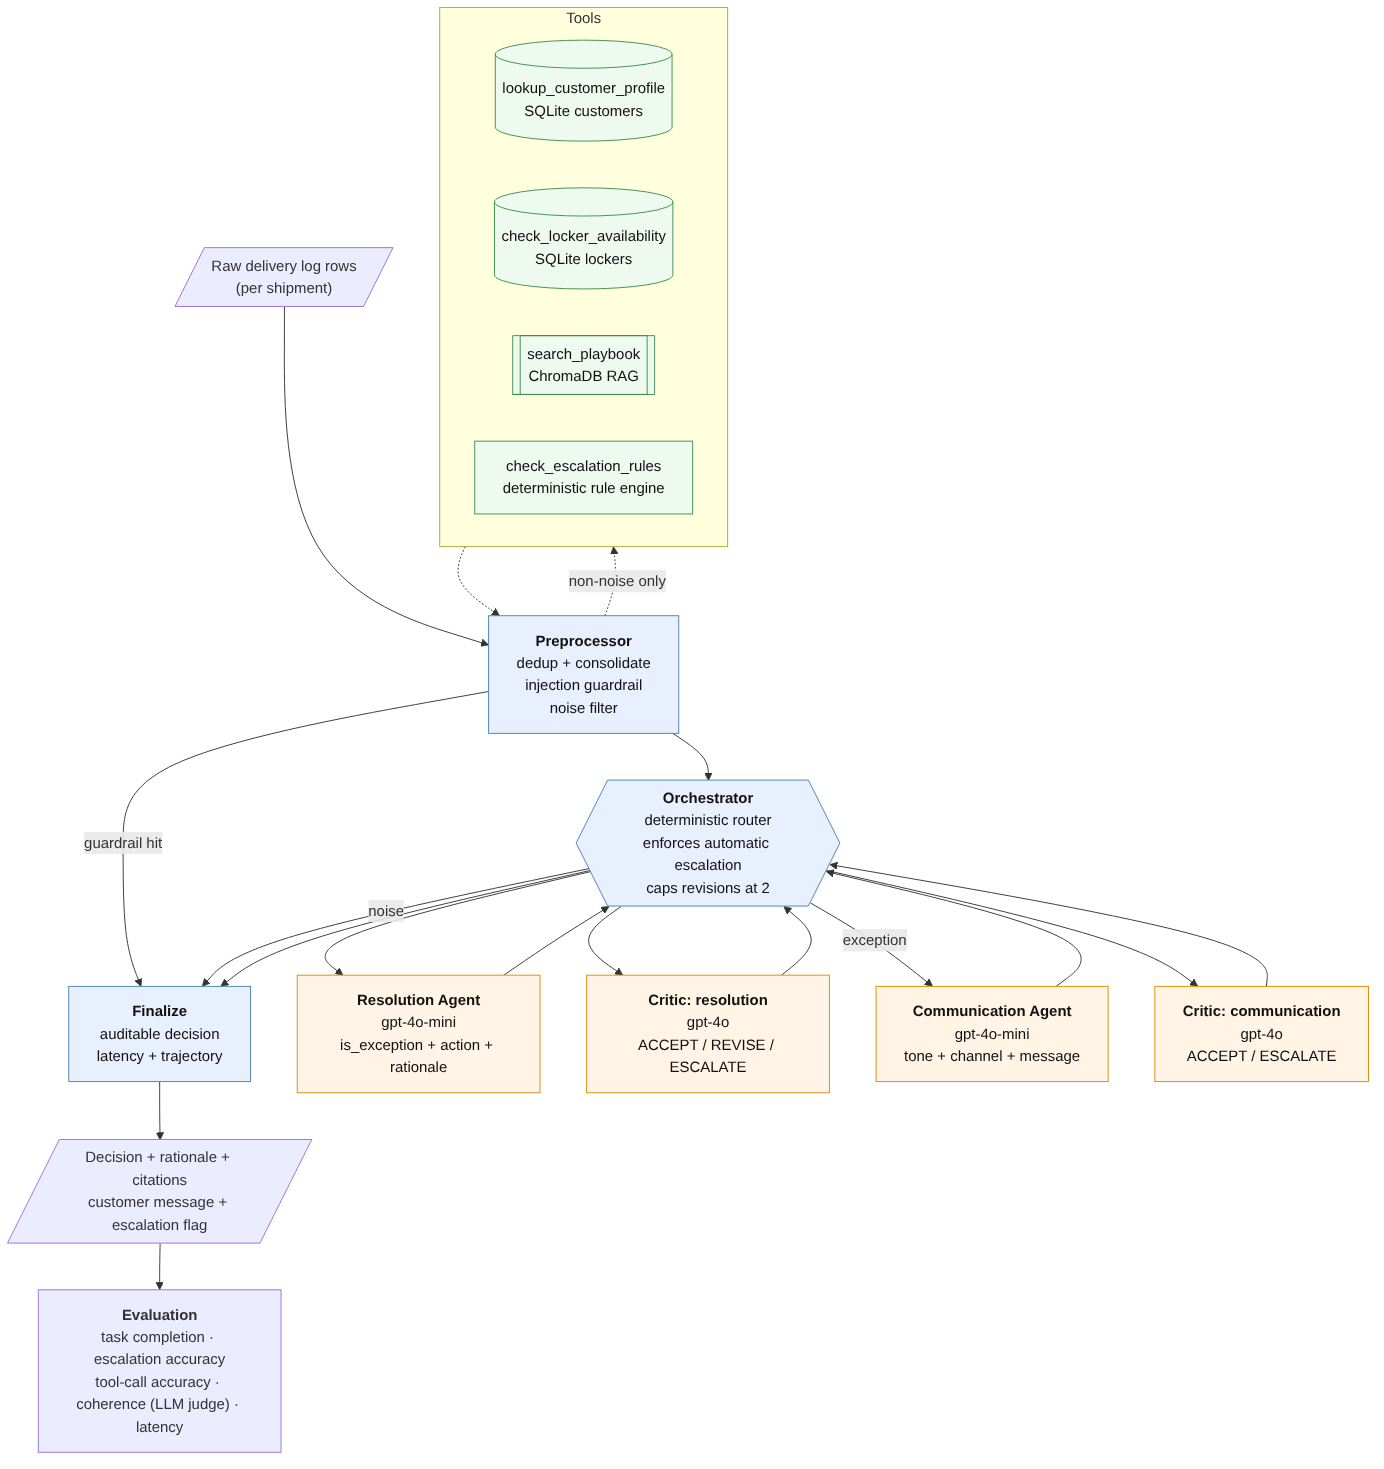

| Component | Type | Responsibility |
|:--|:--|:--|
| **Preprocessor** | deterministic node | De-duplicates scans, consolidates multi-row shipments (highest attempt wins, earlier driver notes preserved), runs the **prompt-injection guardrail**, short-circuits routine **noise** (DELIVERED / SCANNED with no anomaly words), and otherwise calls all five tools to assemble context. |
| **Orchestrator** | deterministic router | Fixed-priority routing: guardrail -> finalize; noise -> finalize; Resolution -> Critic (resolution) -> Communication -> Critic (communication) -> finalize. Enforces the revision cap (2 loops) and **forces escalation on automatic rule-engine triggers** - an LLM cannot talk its way out of a mandatory escalation. |
| **Resolution Agent** | LLM sub-agent (`gpt-4o-mini`) | Classifies exception vs noise and picks exactly one action (RESCHEDULE / REROUTE_TO_LOCKER / REPLACE / RETURN_TO_SENDER) with a step-by-step, page-cited rationale. Output is Pydantic-validated with a consistency validator and retried on failure. |
| **Critic Agent - resolution** | LLM sub-agent (`gpt-4o`) | Independent quality gate: ACCEPT, REVISE (sends feedback back to the Resolution Agent) or ESCALATE (supervisor needed). Honors discretionary escalation triggers - the "use your judgment" cases in the playbook. |
| **Communication Agent** | LLM sub-agent (`gpt-4o-mini`) | Writes the customer notification with tone from tier (VIP/PREMIUM -> FORMAL, STANDARD -> CASUAL), channel from preference (EMAIL/SMS), locker details when rerouting, and a severity-proportional apology. Only this agent receives the customer's name (PII). |
| **Critic Agent - communication** | LLM sub-agent (`gpt-4o`) | Checks tone/channel fit, factual consistency with the resolution, absence of jargon or fabricated promises; ACCEPT or ESCALATE. |
| **Finalize** | deterministic node | Packages the auditable decision, computes end-to-end latency, writes the final trajectory entry. |

**Escalation logic - two layers.** (1) The `check_escalation_rules` tool is a pure rule engine encoding the playbook's Escalation Matrix; its *automatic* triggers are enforced by the orchestrator regardless of what any LLM says. (2) *Discretionary* triggers and playbook situations that require a supervisor are decided by the Critic, which can also escalate when it rejects a resolution twice (revision cap). The aim is high escalation accuracy without over-escalating routine cases.

## Multi-Agent System State


We define a single unified state object that flows through the entire LangGraph pipeline.

- `UnifiedAgentState` carries all the data every node needs - inputs, intermediate results, and final outputs.
- Each node reads the keys it needs from this state and writes its outputs back to it.
- This keeps the pipeline simple and the data flow explicit at every step.


In [18]:
class UnifiedAgentState(TypedDict):
    """State object passed through the LangGraph pipeline."""
    # Input
    raw_rows: list[dict]                                                        # Raw delivery log rows for this shipment
    shipment_id: str

    # Preprocessor output
    consolidated_event: dict                                                     # Deduplicated, consolidated event
    customer_profile: dict                                                       # Profile without PII (no customer name)
    customer_profile_full: dict                                                  # Profile with customer name for personalization
    locker_availability: list[dict]                                              # Lockers in same zip
    playbook_context: list[dict]                                                 # Retrieved playbook chunks with page metadata
    escalation_signals: dict                                                     # Deterministic rule output
    noise_override: bool                                                         # Preprocessor guardrail flag for routine noise
    guardrail_triggered: bool                                                    # True if input injection detected

    # Resolution Agent output
    resolution_output: dict                                                      # {is_exception, resolution, rationale}

    # Critic - resolution validation
    critic_resolution_output: dict                                               # {decision, rationale}
    resolution_revision_count: int                                               # Track retries, max 2
    critic_feedback: str                                                         # Feedback for revision loop

    # Communication Agent output
    communication_output: dict                                                   # {tone_label, communication_message}

    # Critic - communication validation
    critic_communication_output: dict                                            # {decision, rationale}

    # Routing
    next_agent: str                                                              # Next node to route to
    max_loops: int                                                               # Max revision loops

    # Final
    escalated: bool                                                              # Whether any critic node returned ESCALATE
    tool_calls_log: list[str]                                                    # Log of all tool invocations
    trajectory_log: list[str]                                                    # Audit trail of agent decisions
    start_time: Optional[float]                                                  # Pipeline start timestamp
    latency_sec: Optional[float]                                                 # Total pipeline latency
    final_actions: list[dict]                                                    # Final packaged output


## Router Agent

We first define input sanitization and preprocessing helper functions.

- The guardrail scans free-text fields for prompt injection keywords before any LLM receives them.
- Seven helper functions handle the discrete preprocessing steps:
    - deduplication removes repeated scan events,
    - consolidation merges multi-row shipments into a single event while preserving driver notes from prior attempts,
    - injection scanning checks both raw inputs and retrieved RAG chunks,
    - context fetching calls the four context tools (customer profile, lockers, playbook search, escalation rules), and
    - noise detection flags routine status codes with no anomaly indicators.

In [19]:
INJECTION_KEYWORDS = [
    "ignore previous instructions",
    "ignore all instructions",
    "ignore above instructions",
    "you are now a",
    "act as a",
    "system:",
    "override your rules",
    "override the rules",
    "bypass your filters",
    "bypass the safety",
    "jailbreak",
    "pretend you",
    "roleplay as",
    "dan mode",
    "do not follow your rules",
    "disregard your instructions"
]

In [20]:
def scan_for_injection(text: str) -> bool:
    """Returns True if prompt injection keywords are detected in the text."""
    if not text or not isinstance(text, str):
        return False
    text_lower = text.lower()
    return any(keyword in text_lower for keyword in INJECTION_KEYWORDS)

In [21]:
def deduplicate_rows(raw_rows: list[dict]) -> list[dict]:
    """Remove duplicate scan events."""
    return [r for r in raw_rows if r.get("is_duplicate_scan", "False") != "True"]

In [22]:
def consolidate_event(unique_rows: list[dict], raw_rows: list[dict]) -> dict:
    """Consolidate multi-row shipment into a single event using highest attempt number."""
    if unique_rows:
        primary = max(unique_rows, key=lambda r: int(r.get("attempt_number", 0)))
    else:
        primary = raw_rows[0]

    # NEW: Collect driver notes from all prior attempts
    prior_notes = [
        f"Attempt {r['attempt_number']}: {r['status_description']}"
        for r in unique_rows
        if r is not primary
    ]

    return {
        "shipment_id": primary["shipment_id"],
        "timestamp": primary["timestamp"],
        "status_code": primary["status_code"],
        "status_description": primary["status_description"],
        "customer_id": primary["customer_id"],
        "delivery_address": primary["delivery_address"],
        "package_type": primary["package_type"],
        "package_size": primary["package_size"],
        "attempt_number": int(primary["attempt_number"]),
        "prior_attempt_notes": prior_notes,
        "total_rows": len(raw_rows),
        "duplicates_removed": len(raw_rows) - len(unique_rows)
    }

In [23]:
def scan_inputs_for_injection(consolidated: dict, raw_rows: list[dict]) -> bool:
    """Scan all free-text fields in delivery data for prompt injection."""
    texts = [consolidated["status_description"]]
    texts.extend(row.get("status_description", "") for row in raw_rows)
    return any(scan_for_injection(text) for text in texts)

In [24]:
def scan_chunks_for_injection(playbook_context: list[dict]) -> bool:
    """Scan retrieved RAG chunks for prompt injection."""
    return any(scan_for_injection(chunk.get("content", "")) for chunk in playbook_context)

The retrieval query is built from a short **topic hint per status code** (so the semantic search lands in the right playbook section even when the driver note is terse or misspelt), followed by the package type and the raw driver note. A second lookup targeting the **Escalation Matrix** is merged in so the agents always see the escalation rules alongside the situation-specific rules. Duplicate chunks are removed and the page numbers become the document citations.

In [25]:
# Topic hint per status code steers retrieval to the right playbook section
SECTION_HINTS = {
    "ATTEMPTED":     "failed delivery attempt number first second third attempt reattempt locker reroute hold at depot",
    "ADDRESS_ISSUE": "address mismatch building or street not found verify address missing unit invalid address fraud",
    "DAMAGED":       "damaged package assessment minor moderate severe fragile replacement do not deliver",
    "REFUSED":       "refused delivery customer did not order return to sender refusal process",
    "WEATHER_DELAY": "weather delay perishable package 4 hours pull from route replacement",
}


def fetch_context(consolidated: dict, tool_log: list[str]) -> dict:
    """Fetch all context via tools: customer profiles, lockers, playbook, escalation rules."""
    customer_id = consolidated["customer_id"]

    # Profile without PII for the reasoning agents
    customer_profile = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": False}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=False)")

    # Profile with name - only the Communication Agent uses this
    customer_profile_full = lookup_customer_profile.invoke(
        {"customer_id": customer_id, "include_pii": True}
    )
    tool_log.append(f"TOOL: lookup_customer_profile({customer_id}, pii=True)")

    # Zip code is the last comma-separated token of the address
    address_parts = consolidated["delivery_address"].split(",")
    zip_code = address_parts[-1].strip() if address_parts else ""
    locker_availability = check_locker_availability.invoke(
        {"zip_code": zip_code, "package_size": consolidated["package_size"]}
    )
    tool_log.append(f"TOOL: check_locker_availability({zip_code}, {consolidated['package_size']})")

    # RAG lookup 1: situation-specific rules
    hint = SECTION_HINTS.get(consolidated["status_code"], consolidated["status_code"])
    query = f"{hint}. {consolidated['package_type']} package. Driver note: {consolidated['status_description'][:120]}"
    playbook_context = search_playbook.invoke({"query": query})
    tool_log.append("TOOL: search_playbook(situation query)")

    # RAG lookup 2: escalation matrix for this customer tier
    esc_query = (f"escalation matrix automatic and discretionary escalation triggers "
                 f"{customer_profile.get('tier', '')} customer exceptions in last 90 days")
    esc_chunks = search_playbook.invoke({"query": esc_query})
    tool_log.append("TOOL: search_playbook(escalation query)")

    # Merge, dropping duplicate chunks
    seen = set()
    merged_context = []
    for chunk in playbook_context + esc_chunks:
        key = (chunk["page"], chunk["content"][:80])
        if key not in seen:
            seen.add(key)
            merged_context.append(chunk)

    # Deterministic rule engine - authoritative escalation signals
    escalation_signals = check_escalation_rules.invoke({
        "customer_tier": customer_profile.get("tier", "STANDARD"),
        "exceptions_last_90d": customer_profile.get("exceptions_last_90d", 0),
        "attempt_number": consolidated["attempt_number"],
        "package_type": consolidated["package_type"],
        "status_code": consolidated["status_code"],
        "status_description": consolidated["status_description"]
    })
    tool_log.append("TOOL: check_escalation_rules(...)")

    return {
        "customer_profile": customer_profile,
        "customer_profile_full": customer_profile_full,
        "locker_availability": locker_availability,
        "playbook_context": merged_context,
        "escalation_signals": escalation_signals
    }


In [26]:
def check_noise_override(consolidated: dict) -> bool:
    """Flag routine status codes with no anomaly indicators."""
    routine_codes = {"DELIVERED", "IN_TRANSIT", "OUT_FOR_DELIVERY", "SCANNED"}
    if consolidated["status_code"] not in routine_codes:
        return False

    anomaly_indicators = [
        "damage", "wrong", "suspicious", "overdue", "missing",
        "unexpected", "misroute", "lost", "stolen", "abandoned",
        "leak", "crush", "broke", "delay", "late", "fraud"
    ]
    desc = consolidated["status_description"].lower()
    return not any(indicator in desc for indicator in anomaly_indicators)

The preprocessor is the first node in the pipeline. It runs a six-step sequence:
- deduplicate scan events,
- consolidate multi-row shipments,
- scan inputs for prompt injection,
- check for routine noise (skipping tool calls if detected),
- fetch context via tools, and
- scan retrieved RAG chunks for injection.

Early returns on guardrail triggers or noise detection prevent unnecessary LLM calls and tool invocations.

In [27]:
@traceable(name="preprocessor_node")
def preprocessor_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Deduplicates, consolidates, assembles context, and runs input guardrails."""
    tool_log = []
    trajectory = []
    start = time.time()

    # Step 1: Remove duplicate scan events
    unique_rows = deduplicate_rows(state["raw_rows"])
    tool_log.append("PREPROCESSOR: Deduplicated rows")
    trajectory.append(f"preprocessor: {len(state['raw_rows'])} raw rows -> {len(unique_rows)} after dedup")

    # Step 2: Merge multi-row shipments into a single consolidated event
    consolidated = consolidate_event(unique_rows, state["raw_rows"])

    # Step 3: Scan driver notes for prompt injection - block before any LLM call
    if scan_inputs_for_injection(consolidated, state["raw_rows"]):
        tool_log.append("GUARDRAIL: Injection detected in delivery input")
        trajectory.append("preprocessor: Guardrail triggered - prompt injection detected")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Step 4: Check for routine noise before making any tool calls
    noise_override = check_noise_override(consolidated)
    if noise_override:
        tool_log.append("PREPROCESSOR: Noise guardrail - routine status with no anomaly")
        trajectory.append(f"preprocessor: {consolidated['status_code']} flagged as noise by guardrail, skipping tool calls")
        state["consolidated_event"] = consolidated
        state["customer_profile"] = {}
        state["customer_profile_full"] = {}
        state["locker_availability"] = []
        state["playbook_context"] = []
        state["escalation_signals"] = {}
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = True
        state["guardrail_triggered"] = False
        state["escalated"] = False
        state["start_time"] = start
        state["next_agent"] = "orchestrator"
        return state

    # Step 5: Fetch context via tools (only for non-noise cases)
    context = fetch_context(consolidated, tool_log)

    # Step 6: Scan retrieved playbook chunks for injection
    if scan_chunks_for_injection(context["playbook_context"]):
        tool_log.append("GUARDRAIL: Injection detected in retrieved playbook chunk")
        trajectory.append("preprocessor: Guardrail triggered - injection in RAG chunk")
        context["playbook_context"] = []                                         # Drop contaminated chunks
        state["consolidated_event"] = consolidated
        state["customer_profile"] = context["customer_profile"]
        state["customer_profile_full"] = context["customer_profile_full"]
        state["locker_availability"] = context["locker_availability"]
        state["playbook_context"] = context["playbook_context"]
        state["escalation_signals"] = context["escalation_signals"]
        state["tool_calls_log"] = tool_log
        state["trajectory_log"] = trajectory
        state["resolution_revision_count"] = 0
        state["critic_feedback"] = ""
        state["noise_override"] = False
        state["guardrail_triggered"] = True
        state["escalated"] = True
        state["start_time"] = start
        state["next_agent"] = "finalize"
        return state

    # Package all context into state and pass to orchestrator
    state["consolidated_event"] = consolidated
    state["customer_profile"] = context["customer_profile"]
    state["customer_profile_full"] = context["customer_profile_full"]
    state["locker_availability"] = context["locker_availability"]
    state["playbook_context"] = context["playbook_context"]
    state["escalation_signals"] = context["escalation_signals"]
    state["tool_calls_log"] = tool_log
    state["trajectory_log"] = trajectory
    state["resolution_revision_count"] = 0
    state["critic_feedback"] = ""
    state["noise_override"] = noise_override
    state["guardrail_triggered"] = False
    state["escalated"] = False
    state["start_time"] = start
    state["next_agent"] = "orchestrator"
    return state


The orchestrator is a deterministic routing node invoked after every agent completes.
- It reads the current pipeline state and decides the next step in a fixed priority sequence:
    - guardrail-blocked cases go to finalize immediately,
    - noise cases bypass the LLM,
    - exception cases flow through the full Resolution → Critic → Communication → Critic → finalize path, with revision loops capped at 2 retries.
    
Automatic escalation triggers from the rule engine are enforced here, and they cannot be overridden by LLM judgment.

In [28]:
@traceable(name="orchestrator_node")
def orchestrator_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """
    Central router. Determines next_agent based on current state.

    Routing order:
      0. Guardrail triggered                          -> finalize
      1. Noise override from preprocessor             -> finalize (skip LLM)
      2. Resolution not yet run                       -> resolution_agent
      3. Resolution done, critic not yet run          -> critic_resolution
      4. Critic returned REVISE and under loop limit  -> resolution_agent (reset)
      5. Critic returned REVISE and at loop limit     -> force ESCALATE -> communication/finalize
      6. Enforce automatic escalation triggers         (rule engine is authoritative)
      7. Not an exception                             -> finalize
      8. Communication not yet run                    -> communication_agent
      9. Communication done, critic not yet run       -> critic_communication
      10. All done                                    -> finalize
    """
    # 0. Guardrail triggered - no LLM, force escalation, go to finalize
    if state.get("guardrail_triggered"):
        state["resolution_output"] = {
            "is_exception": "YES",
            "resolution": "RESCHEDULE",
            "rationale": "Input flagged by guardrail - prompt injection detected. Defaulting to RESCHEDULE with forced escalation for human review."
        }
        state["escalated"] = True
        state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Guardrail triggered, forcing escalation to finalize")
        return state

    # 1. Noise override - classify as non-exception, skip all agents
    if state.get("noise_override") and not state.get("resolution_output"):
        state["resolution_output"] = {
            "is_exception": "NO",
            "resolution": "N/A",
            "rationale": f"Status code {state['consolidated_event']['status_code']} with routine description. No anomaly indicators. Classified as noise by preprocessor guardrail."
        }
        state["trajectory_log"].append("orchestrator: Noise override from preprocessor, skipping to finalize")
        state["next_agent"] = "finalize"
        return state

    # 2. Resolution Agent hasn't run yet - send it there
    if not state.get("resolution_output"):
        state["next_agent"] = "resolution_agent"
        return state

    # 3. Resolution done but Critic hasn't validated yet
    if not state.get("critic_resolution_output"):
        state["next_agent"] = "critic_resolution"
        return state

    critic_decision = state["critic_resolution_output"].get("decision")

    # 4. Critic wants a revision and we're under the retry limit
    if critic_decision == "REVISE" and state["resolution_revision_count"] < state["max_loops"]:
        state["resolution_output"] = {}                                          # Clear for retry
        state["critic_resolution_output"] = {}                                   # Clear for retry
        state["next_agent"] = "resolution_agent"
        state["trajectory_log"].append(
            f"orchestrator: REVISE loop {state['resolution_revision_count']}/{state['max_loops']}"
        )
        return state

    # 5. Revision limit exhausted - force escalate, still generate communication if exception
    if critic_decision == "REVISE" and state["resolution_revision_count"] >= state["max_loops"]:
        state["escalated"] = True
        state["critic_resolution_output"] = {
            "decision": "ESCALATE",
            "rationale": "Max revision loops reached. Accepting current resolution with escalation."
        }
        if state["resolution_output"].get("is_exception") == "YES":
            state["next_agent"] = "communication_agent"                          # Still notify customer
        else:
            state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Max loops reached, forcing ESCALATE")
        return state

    # 6. Enforce automatic escalation triggers - rule engine is authoritative
    if state.get("escalation_signals", {}).get("has_triggers"):
        automatic = [t for t in state["escalation_signals"].get("triggers", [])
                     if t.startswith("AUTOMATIC")]
        if automatic and state["resolution_output"].get("is_exception") == "YES":
            state["escalated"] = True
            log_line = f"orchestrator: Forced escalation from rule engine - {automatic}"
            if log_line not in state["trajectory_log"]:                         # Log once, not on every routing pass
                state["trajectory_log"].append(log_line)

    # 7. Not an exception - no customer message needed, go to finalize
    if state["resolution_output"].get("is_exception") == "NO":
        state["next_agent"] = "finalize"
        state["trajectory_log"].append("orchestrator: Not an exception, skipping to finalize")
        return state

    # 8. Communication Agent hasn't run yet
    if not state.get("communication_output"):
        state["next_agent"] = "communication_agent"
        return state

    # 9. Communication done but Critic hasn't validated yet
    if not state.get("critic_communication_output"):
        state["next_agent"] = "critic_communication"
        return state

    # 10. Everything complete - finalize
    state["next_agent"] = "finalize"
    return state


This is the final node in the pipeline.
- It packages all results into a structured output dict, computes end-to-end latency, and logs the final action to the trajectory.
- Guardrail-blocked cases produce a distinct output with `guardrail_blocked: True` so evaluation can handle them separately.

In [29]:
@traceable(name="finalize_node")
def finalize_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Packages final results and records end time."""
    # Guardrail-blocked cases get a distinct safe output
    if state.get("guardrail_triggered"):
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": "BLOCKED",
            "resolution": "ESCALATED",
            "escalated": True,
            "tone": "N/A",
            "message": "This shipment was flagged by the input guardrail and requires human review.",
            "revision_count": 0,
            "guardrail_blocked": True
        }
    else:
        # Normal case - package predictions from all agents
        final = {
            "shipment_id": state["shipment_id"],
            "is_exception": state.get("resolution_output", {}).get("is_exception", "ERROR"),
            "resolution": state.get("resolution_output", {}).get("resolution", "ERROR"),
            "escalated": state["escalated"],
            "tone": state.get("communication_output", {}).get("tone_label", "N/A"),
            "message": state.get("communication_output", {}).get("communication_message", ""),
            "revision_count": state["resolution_revision_count"],
            "guardrail_blocked": False
        }

    # Compute total pipeline latency
    latency = time.time() - state["start_time"] if state.get("start_time") else 0.0

    # Write final output back to state
    state["final_actions"] = [final]
    state["latency_sec"] = latency
    state["next_agent"] = "END"

    # Log the final action and latency to the audit trail
    state["trajectory_log"].append(
        f"finalize: actions={json.dumps(final)}; latency={latency:.3f}s"
    )

    return state


## Resolution Agent

We first define the output schema for the Resolution Agent.
- A Pydantic model validator enforces mutual consistency between is_exception and resolution.
- If the LLM produces a contradictory pair (e.g., `exception="YES"` with `resolution="N/A"`), the validation fails and the structured output call retries.

In [30]:
class ResolutionOutput(BaseModel):
    """Resolution Agent output schema."""
    # Whether this delivery event requires action
    is_exception: Literal["YES", "NO"] = Field(
        description="Whether this delivery event is a real actionable exception"
    )
    # What action to take - must be N/A when not an exception
    resolution: Literal[
        "RESCHEDULE", "REROUTE_TO_LOCKER", "REPLACE", "RETURN_TO_SENDER", "N/A"
    ] = Field(
        description="Resolution action. N/A if is_exception is NO"
    )
    # Explanation of the decision for auditability
    rationale: str = Field(
        description="Step-by-step reasoning for the classification and resolution decision"
    )

    @model_validator(mode="after")
    def validate_consistency(self):
        """Enforce that is_exception and resolution are mutually consistent."""
        if self.is_exception == "YES" and self.resolution == "N/A":
            raise ValueError("resolution cannot be N/A when is_exception is YES")
        if self.is_exception == "NO" and self.resolution != "N/A":
            raise ValueError("resolution must be N/A when is_exception is NO")
        return self

Next, we define the Resolution Agent's system prompt, which defines the agent's role, classification rules, resolution guidelines, and consistency constraints.

In [31]:
RESOLUTION_AGENT_SYSTEM_PROMPT = """You are the Resolution Agent for a last-mile delivery operations team. Your job is to
(1) decide whether a consolidated delivery event is a real, actionable exception or routine operational noise, and
(2) if it is an exception, select exactly ONE resolution action by following the Exception Resolution Playbook
excerpts provided, the customer profile, locker availability and the deterministic escalation signals.

INPUTS YOU RECEIVE
- DELIVERY EVENT: the de-duplicated, consolidated shipment event (highest attempt number) plus notes from earlier attempts.
- CUSTOMER PROFILE: tier (STANDARD / PREMIUM / VIP), preferred channel, exceptions_last_90d, active_credit. No PII.
- LOCKER AVAILABILITY: lockers in the delivery zip code with an `eligible` flag and the reason.
- ESCALATION SIGNALS: output of the deterministic rule engine. It is authoritative - acknowledge it, never contradict it.
- RELEVANT PLAYBOOK SECTIONS: retrieved excerpts tagged [Page N]. Cite the pages you rely on.

STEP 1 - CLASSIFICATION (is_exception)
- NO  : status_code DELIVERED, SCANNED, IN_TRANSIT or OUT_FOR_DELIVERY with no anomaly in the notes -> routine noise; resolution must be "N/A".
- YES : ATTEMPTED, ADDRESS_ISSUE, DAMAGED, REFUSED, WEATHER_DELAY, or a routine code whose notes describe damage, loss, misrouting or another anomaly.

STEP 2 - RESOLUTION (exactly one of RESCHEDULE, REROUTE_TO_LOCKER, REPLACE, RETURN_TO_SENDER)
Failed attempts (ATTEMPTED) - use attempt_number of the consolidated event:
  - Attempt 1 : RESCHEDULE redelivery for the next business day.
  - Attempt 2 : offer options. Choose REROUTE_TO_LOCKER only if at least one locker is eligible AND the package is not PERISHABLE;
                VIP customers should be offered redelivery with a time window instead. Otherwise RESCHEDULE.
  - Attempt 3+: this is the escalation threshold - never schedule a 4th attempt yourself. For non-perishable packages the
                resolution is REROUTE_TO_LOCKER so the package leaves the failed-redelivery cycle. If no locker in the zip is
                eligible (for example it is FULL), STILL select REROUTE_TO_LOCKER and state in the rationale that the supervisor
                must authorise an alternative / adjacent-zip locker or a courtesy redelivery. For PERISHABLE packages on a 3rd
                attempt choose REPLACE (perishables are never held at the depot).
Address issues (ADDRESS_ISSUE):
  - Building / street not found, or missing unit number: RESCHEDULE - hold at depot, contact the customer to verify or complete
    the address (48 h window, 72 h for VIP), then redeliver.
  - Clearly invalid address (vacant lot, demolished building, construction site, empty lot): RETURN_TO_SENDER with fraud review.
Damaged packages (DAMAGED):
  - Minor cosmetic damage on a STANDARD package (small dent, torn label, light scuffing): RESCHEDULE - proceed with delivery and note the damage.
  - Moderate or severe damage (crushed, partially open, leaking, odor, contents visible): REPLACE.
  - FRAGILE packages: lower the threshold - minor becomes moderate, so a dented or crushed FRAGILE box is REPLACE.
  - Any damaged PERISHABLE (leaking, spoiled, odor): REPLACE - do not deliver under any circumstances.
Refused deliveries (REFUSED): RETURN_TO_SENDER (accept the refusal, never argue; flag "didn't order it" cases for customer-service review).
Weather delays (WEATHER_DELAY):
  - PERISHABLE with an estimated delay of more than 4 hours, or an unknown duration: REPLACE - pull from the route immediately.
  - PERISHABLE with a delay of 4 hours or less, and all non-perishable packages: RESCHEDULE with an updated delivery window.
Locker rules (always): never reroute PERISHABLE packages; never reroute to a FULL locker; LIMITED lockers accept SMALL only;
the package size must fit the locker's maximum size.

STEP 3 - RATIONALE
Write a numbered, step-by-step rationale: (1) classification and why, (2) the playbook rule applied with [Page N] citations,
(3) customer tier and exception history considered, (4) locker check result, (5) escalation signals noted, (6) final action.
Be concrete and auditable. Use only facts present in the inputs - never invent details.

CONSISTENCY RULES
- is_exception = YES -> resolution must NOT be N/A.
- is_exception = NO  -> resolution must be N/A.
- The rule engine's escalation signals are facts, not something you decide; just reflect them in the rationale.{critic_feedback}"""


The `{critic_feedback}` placeholder at the end of the prompt is where the Critic's feedback is injected on a revision loop; on the first pass it is empty.

Next, we define a helper function that formats retrieved playbook chunks into a single string with page references.

In [32]:
def format_playbook_context(playbook: list[dict]) -> str:
    """Format playbook chunks with page references for LLM context."""
    # Combine all chunks with page labels and separator lines
    return "\n\n---\n\n".join(
        [f"[Page {c['page']}] {c['content']}" for c in playbook]
    )

Finally, we define the Resolution Agent node. It

- reads the consolidated event, customer profile, locker availability, escalation signals, and playbook context from state,
- builds the system prompt with optional Critic feedback for revision loops,
- invokes the LLM with structured output and retries on validation failures,
- writes the resolution decision back to state and logs the invocation.


In [33]:
@traceable(name="resolution_agent_node")
def resolution_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Resolution Agent: classifies exception and decides resolution action."""
    # If this is a revision attempt, append the Critic's feedback to the prompt
    feedback = state.get("critic_feedback", "")
    feedback_section = ""
    if feedback:
        feedback_section = (
            f"\n\nPREVIOUS ATTEMPT WAS REJECTED. Critic feedback:\n{feedback}\n"
            f"Revise your decision based on this feedback."
        )

    # Build the system prompt with optional feedback section
    system_prompt = RESOLUTION_AGENT_SYSTEM_PROMPT.format(critic_feedback=feedback_section)

    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context into the user message
    user_content = (
        f"DELIVERY EVENT:\n{json.dumps(state['consolidated_event'], indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"RELEVANT PLAYBOOK SECTIONS:\n{playbook_text}"
    )

    # Invoke LLM with Pydantic-enforced structured output
    structured_llm = gen_llm.with_structured_output(ResolutionOutput)
    max_retries = 3
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke([
                SystemMessage(content=system_prompt),
                HumanMessage(content=user_content)
            ])
            break                                                                # Valid output, exit retry loop
        except Exception as e:
            if attempt < max_retries - 1:
                # Log the failure and retry
                state["trajectory_log"].append(
                    f"resolution_agent: Validation failed (attempt {attempt + 1}), retrying - {str(e)[:100]}"
                )
            else:
                # All retries exhausted - safe fallback with forced escalation
                result = ResolutionOutput(
                    is_exception="YES",
                    resolution="RESCHEDULE",
                    rationale=(
                        f"Resolution agent failed after {max_retries} attempts. "
                        f"Defaulting to RESCHEDULE with escalation. Last error: {str(e)[:200]}"
                    )
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    f"resolution_agent: All {max_retries} retries exhausted, "
                    f"defaulting to RESCHEDULE with forced escalation"
                )

    # Write resolution decision back to state
    state["resolution_output"] = result.model_dump()

    # Log the invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: resolution_agent invoked")
    state["trajectory_log"].append(
        f"resolution_agent: is_exception={result.is_exception}, resolution={result.resolution}"
    )
    state["next_agent"] = "orchestrator"
    return state


## Communication Agent

We first define the output schema for the Communication Agent.
- Two required fields: tone label and the customer message.
- No model validator needed here since both fields are always required and have no cross-field dependencies.

In [34]:
class CommunicationOutput(BaseModel):
    """Communication Agent output schema."""
    # Tone inferred from customer tier: VIP/PREMIUM -> FORMAL, STANDARD -> CASUAL
    tone_label: Literal["FORMAL", "CASUAL"] = Field(
        description="Tone of the customer message, inferred from customer tier"
    )
    # The actual notification text sent to the customer
    communication_message: str = Field(
        description="The customer-facing notification message"
    )

Next, we define the Communication Agent's system prompt. It fixes the tone to the customer tier (VIP/PREMIUM formal, STANDARD casual), formats the message for the preferred channel (email vs SMS), spells out what each resolution means for the customer, scales the apology to severity, and forbids internal jargon, tier names and promises that are not in the context.

In [35]:
COMMUNICATION_AGENT_SYSTEM_PROMPT = """You are the Customer Communication Agent for a last-mile delivery operator. You write the single
customer-facing notification for a delivery exception AFTER the resolution has been decided. You receive a CONTEXT block
(customer name, tier, preferred channel, active credit, exception type, driver note, package type, resolution and its
rationale) and, for locker reroutes, an optional LOCKER FOR REROUTE block.

TONE (tone_label) - derived strictly from the customer tier:
- VIP or PREMIUM -> FORMAL : structured, polite, full sentences, professional greeting and sign-off.
- STANDARD       -> CASUAL : friendly and conversational, brief - but never flippant about the problem.

CHANNEL - match preferred_channel:
- EMAIL : start with a one-line subject (e.g. "Subject: Update on your delivery"), greet the customer by name, sign off as "The Delivery Team".
- SMS   : keep it under about 320 characters, no subject line, first name only, plain text.

CONTENT - every message must contain, in this order:
1. What happened - plain language, never a status code or internal jargon.
2. What we are doing - the specific resolution:
   - RESCHEDULE        : for failed attempts, redelivery on the next business day (VIP: offer to agree a delivery time window).
                         For address problems, ask the customer to confirm or update the address within 48 hours (72 hours for VIP)
                         and say redelivery will be scheduled as soon as the address is confirmed - do NOT promise a specific
                         redelivery day before the address is confirmed.
   - REROUTE_TO_LOCKER : if LOCKER FOR REROUTE is provided, include the locker address, operating hours, the 3-business-day pickup
                         deadline and the option to request home redelivery instead (about 2 extra business days). If no locker
                         details are provided, say only that a convenient pickup location is being arranged and the details will
                         follow shortly - never tell the customer that a locker is full, unavailable or needs approval.
   - REPLACE           : a replacement is being arranged with the sender; the customer does not need to accept or return the damaged / affected item.
   - RETURN_TO_SENDER  : confirm the refusal has been processed and the item is being returned to the sender; no action needed.
3. What happens next - the timeline and any action required from the customer.
4. An apology proportional to severity: a brief acknowledgement for a first failed attempt; a sincere, detailed apology for damaged
   or spoiled goods, especially perishables and VIP customers.

SERVICE CREDITS - if active_credit is greater than 0, acknowledge that this is not the customer's first issue and that their
existing credit remains on the account. A goodwill service credit (no dollar amount) may be mentioned only in the two cases the
policy allows: a VIP customer with a damaged package, or a PREMIUM / VIP customer whose perishable order is being replaced after
a weather delay. Never promise refunds, compensation amounts or discounts.

GUARDRAILS - use only facts from CONTEXT; do not mention escalation, supervisors, playbooks or rule engines; never state the
customer's tier, status or membership level (no "VIP", "Premium", "valued-tier"); for WEATHER_DELAY describe the item as delayed or
no longer safe to deliver - never as damaged; do not add promises that are not in the context (no "at no cost to you", no refunds);
do not blame the customer or the driver; no emojis; do not invent tracking links, order numbers or exact times."""


Next, we define a helper function that builds the context dictionary and locker info string from the Communication Agent's view.
- Extracts only the fields needed for message generation - customer name, tier, channel, credit, exception details, and resolution.
- If the resolution is a locker reroute, includes the first eligible locker's details for the notification.

In [36]:
def build_communication_context(state: UnifiedAgentState) -> tuple[dict, str]:
    """Build the context dict and locker info string for the Communication Agent."""
    event = state["consolidated_event"]
    profile = state["customer_profile_full"]
    resolution = state["resolution_output"]
    lockers = state["locker_availability"]

    # Include locker details only if the resolution is a reroute
    locker_info = ""
    if resolution.get("resolution") == "REROUTE_TO_LOCKER":
        eligible = [l for l in lockers if l.get("eligible")]
        if eligible:
            locker_info = f"\nLOCKER FOR REROUTE:\n{json.dumps(eligible[0], indent=2)}"

    # Assemble the context the LLM needs for message generation
    comm_context = {
        "customer_name": profile.get("name", "Customer"),
        "customer_tier": profile.get("tier"),
        "preferred_channel": profile.get("preferred_channel"),
        "active_credit": profile.get("active_credit", 0),
        "exception_type": event["status_code"],
        "status_description": event["status_description"],
        "package_type": event["package_type"],
        "resolution": resolution.get("resolution"),
        "resolution_rationale": resolution.get("rationale")
    }

    return comm_context, locker_info


Finally, we define the Communication Agent node. It

- reads the consolidated event, full customer profile, locker availability, and resolution decision from state,
- builds the message context and invokes the LLM with structured output,
- retries on validation failures and falls back to a safe generic message with forced escalation,
- writes the customer message back to state and logs the invocation.


In [37]:
@traceable(name="communication_agent_node")
def communication_agent_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Communication Agent: generates the customer notification."""
    # Build the context and locker info from state
    comm_context, locker_info = build_communication_context(state)

    # Assemble the user message for the LLM
    user_content = f"CONTEXT:\n{json.dumps(comm_context, indent=2)}\n{locker_info}"

    # Invoke LLM with retry on failures
    structured_llm = gen_llm.with_structured_output(CommunicationOutput)
    max_retries = 3                                                                 # Same retry budget as the Resolution Agent
    result = None

    for attempt in range(max_retries):
        try:
            result = structured_llm.invoke([
                SystemMessage(content=COMMUNICATION_AGENT_SYSTEM_PROMPT),
                HumanMessage(content=user_content)
            ])
            break                                                                # Valid output, exit retry loop
        except Exception as e:
            if attempt < max_retries - 1:
                # Log failure and retry
                state["trajectory_log"].append(
                    f"communication_agent: Validation failed (attempt {attempt + 1}), retrying - {str(e)[:100]}"
                )
            else:
                # All retries exhausted - generate a safe generic message
                tier = state["customer_profile_full"].get("tier", "STANDARD")
                result = CommunicationOutput(
                    tone_label="FORMAL" if tier in ("VIP", "PREMIUM") else "CASUAL",
                    communication_message="We're aware of an issue with your delivery and are working to resolve it. A team member will follow up shortly."
                )
                state["escalated"] = True
                state["trajectory_log"].append(
                    f"communication_agent: All {max_retries} retries exhausted, "
                    f"defaulting to generic message with forced escalation"
                )

    # Write customer message back to state
    state["communication_output"] = result.model_dump()

    # Log the invocation and tone decision to shared audit trails
    state["tool_calls_log"].append("AGENT: communication_agent invoked")
    state["trajectory_log"].append(f"communication_agent: tone={result.tone_label}")
    state["next_agent"] = "orchestrator"
    return state


## Critic Agent

We first define the output schema for the Critic Agent.

The resolution validation schema allows three decisions, ACCEPT, ESCALATE, or REVISE, while the communication validation schema only allows ACCEPT or ESCALATE (no revision loop for messages).

Both include a rationale field for auditability.

In [38]:
class CriticResolutionOutput(BaseModel):
    """Critic Agent - resolution validation output."""
    # ACCEPT: valid, ESCALATE: needs supervisor, REVISE: send back to Resolution Agent
    decision: Literal["ACCEPT", "ESCALATE", "REVISE"] = Field(
        description="ACCEPT: valid. ESCALATE: needs supervisor. REVISE: send back to Resolution Agent."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

In [39]:
class CriticCommunicationOutput(BaseModel):
    """Critic Agent - communication validation output."""
    # ACCEPT: appropriate message, ESCALATE: needs supervisor review before sending
    decision: Literal["ACCEPT", "ESCALATE"] = Field(
        description="ACCEPT: message is appropriate. ESCALATE: needs supervisor review."
    )
    # Explanation for the validation decision
    rationale: str = Field(description="Reasoning for the validation decision")

Next, we define two system prompts - one for resolution validation and one for communication validation. The resolution critic applies a fixed decision order (REVISE only for a wrong action or classification; ESCALATE whenever the rule engine or the playbook requires a supervisor; otherwise ACCEPT) with explicit calibration so that correct decisions are not sent back on wording grounds. The communication critic works through a checklist of tone, content, consistency with the resolution, jargon and channel fit, and escalates only when a human must edit the message.

In [40]:
CRITIC_RESOLUTION_SYSTEM_PROMPT = """You are the Critic Agent - the quality gate of an automated delivery-exception pipeline. You validate the
Resolution Agent's decision against the playbook excerpts, the customer context, locker availability and the deterministic
ESCALATION SIGNALS. You never rewrite the decision yourself; you return exactly one of ACCEPT, REVISE or ESCALATE with a rationale.

DECISION RULES - apply in this order:
1. REVISE when the resolution contradicts the playbook or the data. Examples: REROUTE_TO_LOCKER for a PERISHABLE package;
   REROUTE_TO_LOCKER on a 1st or 2nd attempt when no locker is eligible; RESCHEDULE for a REFUSED delivery; RESCHEDULE for a
   leaking / spoiled perishable or for a crushed or dented FRAGILE package (fragile lowers the damage threshold, so it must be
   REPLACE); REPLACE for a routine first failed attempt; is_exception = NO for an ATTEMPTED / ADDRESS_ISSUE / DAMAGED / REFUSED /
   WEATHER_DELAY event; a rationale that relies on facts not present in the inputs. Give specific, actionable feedback.
2. ESCALATE when the resolution is acceptable BUT a supervisor must be involved, i.e. ESCALATION SIGNALS.has_triggers is true
   (automatic OR discretionary triggers - the playbook says it is better to flag something that turns out fine than to miss
   something that needs attention), or the playbook explicitly requires supervisor action: third failed attempt, VIP with 3 or
   more exceptions in 90 days, damaged perishable, perishable weather delay over 4 hours, suspected fraud, Standard customer
   with more than 5 exceptions in 90 days. Note: a 3rd-attempt REROUTE_TO_LOCKER with no eligible locker is the CORRECT
   resolution and must be ESCALATE (the supervisor finds an alternative locker), not REVISE.
3. ACCEPT when the resolution follows the playbook AND ESCALATION SIGNALS.has_triggers is false AND no playbook rule requires a
   supervisor. Do not escalate routine cases such as a Standard customer's first address problem or a simple refusal with no
   triggers - unnecessary escalations waste supervisor capacity.

IMPORTANT CALIBRATION
- REVISE is reserved for a WRONG action or a WRONG classification. Never REVISE because the rationale could be worded better,
  because it mentions an unused locker, or because it omits a detail - note such things in your rationale and ACCEPT.
- "Building / street not found" and "missing unit number" address issues map to RESCHEDULE (hold at depot, verify the address,
  then redeliver) - that is the correct playbook action; only a clearly invalid address (vacant lot, demolished) is RETURN_TO_SENDER.
- Sending a correct decision back twice forces an unnecessary escalation, which is itself an error.

RATIONALE: 2-4 sentences. Cite the playbook page(s) and name the specific trigger or rule you relied on."""


In [41]:
CRITIC_COMMUNICATION_SYSTEM_PROMPT = """You are the Critic Agent reviewing a customer notification before it is sent. You receive the validation context
(tier, preferred channel, active credit, resolution, exception type, package type) and the Communication Agent's output
(tone_label and message). Return ACCEPT or ESCALATE with a short rationale.

CHECKLIST
- Tone label matches the tier: VIP / PREMIUM must be FORMAL, STANDARD must be CASUAL - and the message actually reads in that tone.
- The message explains what happened, the resolution being pursued, what happens next, and includes an apology proportional to severity.
- The message is consistent with the resolution (a REPLACE message must not promise redelivery of the same item; a RETURN_TO_SENDER
  message must confirm the return; a locker reroute must either give locker details or say they will follow).
- No internal jargon (escalation, supervisor, playbook, tier names, "locker is full"), no fabricated promises (new refund or
  credit dollar amounts, exact times, tracking links not in the context), no blame, no PII beyond the customer's own name.
  Referencing the customer's existing active_credit from the context, or saying a goodwill credit "will be added" for a VIP
  damaged package without naming an amount, is allowed by policy.
- Channel fit: SMS messages are short and plain; EMAIL messages have a subject, greeting and sign-off.

DECISION
- ACCEPT if every checklist item passes, or the only issues are cosmetic or improvable wording (length slightly over, a
  timeline phrased more confidently than ideal, a missing nicety). Timelines that come from the context or the playbook
  (48 h / 72 h address confirmation, next-business-day redelivery, 3-day locker pickup) are legitimate and never a reason to escalate.
- ESCALATE only when a human MUST edit the message before it is sent: the tone label is wrong for the tier, the message
  contradicts the resolution (e.g. promises redelivery of an item being replaced or returned), it invents a refund / compensation
  amount or a tracking link, or it contains language that could damage the customer relationship. Escalating a message pulls
  a supervisor off other work, so reserve it for these cases.

RATIONALE: 1-3 sentences naming the checklist items that passed or failed."""


Next, we define two helper functions that build the user content strings for each Critic node from state.


In [42]:
def build_critic_resolution_context(state: UnifiedAgentState) -> str:
    """Build the user content string for resolution validation from state."""
    # Format playbook chunks with page references
    playbook_text = format_playbook_context(state["playbook_context"])

    # Assemble all context the Critic needs to validate the resolution
    return (
        f"DELIVERY EVENT:\n{json.dumps(state['consolidated_event'], indent=2)}\n\n"
        f"CUSTOMER PROFILE:\n{json.dumps(state['customer_profile'], indent=2)}\n\n"
        f"LOCKER AVAILABILITY:\n{json.dumps(state['locker_availability'], indent=2)}\n\n"
        f"ESCALATION SIGNALS:\n{json.dumps(state['escalation_signals'], indent=2)}\n\n"
        f"PLAYBOOK CONTEXT:\n{playbook_text}\n\n"
        f"RESOLUTION AGENT OUTPUT:\n{json.dumps(state['resolution_output'], indent=2)}"
    )


In [43]:
def build_critic_communication_context(state: UnifiedAgentState) -> str:
    """Build the user content string for communication validation from state."""
    # Extract only the fields needed to validate the message
    validation_context = {
        "customer_tier": state["customer_profile"].get("tier"),
        "preferred_channel": state["customer_profile"].get("preferred_channel"),
        "active_credit": state["customer_profile"].get("active_credit", 0),
        "resolution": state["resolution_output"].get("resolution"),
        "exception_type": state["consolidated_event"]["status_code"],
        "package_type": state["consolidated_event"]["package_type"]
    }

    return (
        f"VALIDATION CONTEXT:\n{json.dumps(validation_context, indent=2)}\n\n"
        f"COMMUNICATION AGENT OUTPUT:\n{json.dumps(state['communication_output'], indent=2)}"
    )


Finally, we define the two nodes of the Critic Agent.

The Critic's resolution validation node

- reads the consolidated event, customer profile, locker availability, escalation signals, playbook context, and Resolution Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT, REVISE, or ESCALATE,
- on REVISE, increments the retry counter and stores feedback for the Resolution Agent to use,
- writes the decision back to state and logs the invocation.


In [44]:
@traceable(name="critic_resolution_node")
def critic_resolution_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Critic Agent: validates resolution decision against playbook and context."""
    # Build the full validation context from state
    user_content = build_critic_resolution_context(state)

    # Invoke eval LLM with structured output
    structured_llm = eval_llm.with_structured_output(CriticResolutionOutput)
    result = structured_llm.invoke([
        SystemMessage(content=CRITIC_RESOLUTION_SYSTEM_PROMPT),
        HumanMessage(content=user_content)
    ])

    # Write the Critic's decision back to state
    state["critic_resolution_output"] = result.model_dump()

    # Set escalation flag if Critic says this needs supervisor attention
    if result.decision == "ESCALATE":
        state["escalated"] = True

    # On REVISE, increment the retry counter and store feedback for Resolution Agent
    if result.decision == "REVISE":
        state["resolution_revision_count"] += 1
        state["critic_feedback"] = result.rationale

    # Log invocation and decision to shared audit trails (include the feedback so revision loops are auditable)
    state["tool_calls_log"].append("AGENT: critic_resolution invoked")
    detail = f" - {result.rationale[:220]}" if result.decision != "ACCEPT" else ""
    state["trajectory_log"].append(f"critic_resolution: decision={result.decision}{detail}")
    state["next_agent"] = "orchestrator"
    return state


The Critic's communication validation node

- reads the consolidated event, customer profile, Resolution Agent output, and Communication Agent output from state,
- invokes the eval LLM with structured output to decide ACCEPT or ESCALATE (there is no revision loop for messages),
- writes the decision back to state and logs the invocation.


In [45]:
@traceable(name="critic_communication_node")
def critic_communication_node(state: UnifiedAgentState) -> UnifiedAgentState:
    """Critic Agent: validates customer communication quality."""
    # Build focused validation context from state
    user_content = build_critic_communication_context(state)

    # Invoke eval LLM with structured output
    structured_llm = eval_llm.with_structured_output(CriticCommunicationOutput)
    result = structured_llm.invoke([
        SystemMessage(content=CRITIC_COMMUNICATION_SYSTEM_PROMPT),
        HumanMessage(content=user_content)
    ])

    # Write the Critic's decision back to state
    state["critic_communication_output"] = result.model_dump()

    # Set escalation flag if message needs supervisor review
    if result.decision == "ESCALATE":
        state["escalated"] = True

    # Log invocation and decision to shared audit trails
    state["tool_calls_log"].append("AGENT: critic_communication invoked")
    state["trajectory_log"].append(f"critic_communication: decision={result.decision}")
    state["next_agent"] = "orchestrator"
    return state


# **Multi-Agent Workflow**

We now define the LangGraph workflow. Two tiny routing functions read `next_agent` from the state; the orchestrator is the only node with fan-out edges, and every sub-agent has a single edge back to the orchestrator (hub-and-spoke). The compiled `app` is what each test case invokes.

In [46]:
def route_from_preprocessor(state: UnifiedAgentState) -> str:
    """Preprocessor either hands over to the orchestrator or jumps straight to finalize (guardrail hit)."""
    return state["next_agent"]


def route_from_orchestrator(state: UnifiedAgentState) -> str:
    """Orchestrator decides the next sub-agent (or finalize) and stores it in next_agent."""
    return state["next_agent"]


# Build the graph over the unified state
workflow = StateGraph(UnifiedAgentState)

# Nodes - one per component of the architecture
workflow.add_node("preprocessor", preprocessor_node)
workflow.add_node("orchestrator", orchestrator_node)
workflow.add_node("resolution_agent", resolution_agent_node)
workflow.add_node("critic_resolution", critic_resolution_node)
workflow.add_node("communication_agent", communication_agent_node)
workflow.add_node("critic_communication", critic_communication_node)
workflow.add_node("finalize", finalize_node)

# Entry point
workflow.add_edge(START, "preprocessor")

# Preprocessor -> orchestrator (normal) or finalize (guardrail)
workflow.add_conditional_edges(
    "preprocessor",
    route_from_preprocessor,
    {"orchestrator": "orchestrator", "finalize": "finalize"}
)

# Orchestrator fans out to every sub-agent or to finalize
workflow.add_conditional_edges(
    "orchestrator",
    route_from_orchestrator,
    {
        "resolution_agent": "resolution_agent",
        "critic_resolution": "critic_resolution",
        "communication_agent": "communication_agent",
        "critic_communication": "critic_communication",
        "finalize": "finalize",
    }
)

# Every sub-agent reports back to the orchestrator (hub-and-spoke)
for agent in ["resolution_agent", "critic_resolution", "communication_agent", "critic_communication"]:
    workflow.add_edge(agent, "orchestrator")

# Finalize ends the run
workflow.add_edge("finalize", END)

# Compile into a runnable application
app = workflow.compile()

print("Nodes:", [n for n in app.get_graph().nodes if n not in ("__start__", "__end__")])
print("Edges:", len(app.get_graph().edges))


Nodes: ['preprocessor', 'orchestrator', 'resolution_agent', 'critic_resolution', 'communication_agent', 'critic_communication', 'finalize']
Edges: 13


We now visualize the compiled workflow.

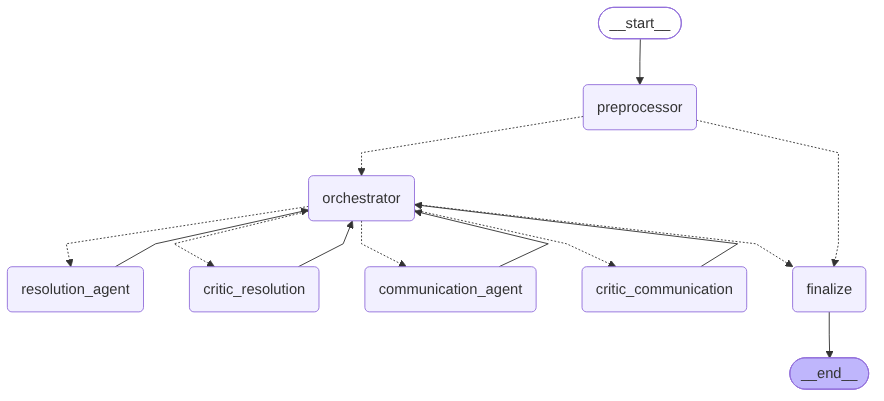

(rendered locally with Mermaid CLI - mermaid.ink not reachable from this environment)


In [47]:
# Render the compiled graph. draw_mermaid_png() uses the mermaid.ink service; if that is unreachable, try a local
# Mermaid CLI (mmdc); if neither is available, print the Mermaid definition.
import shutil, subprocess, tempfile

mermaid_src = app.get_graph().draw_mermaid()
try:
    graph_png = app.get_graph().draw_mermaid_png()
    display(Image(graph_png))
except Exception as e:
    if shutil.which("mmdc"):
        with tempfile.TemporaryDirectory() as td:
            mmd, png = os.path.join(td, "workflow.mmd"), os.path.join(td, "workflow.png")
            open(mmd, "w").write(mermaid_src)
            subprocess.run(["mmdc", "-i", mmd, "-o", png, "-w", "900", "-b", "white"], check=True, capture_output=True)
            display(Image(open(png, "rb").read()))
        print("(rendered locally with Mermaid CLI - mermaid.ink not reachable from this environment)")
    else:
        print(f"PNG rendering unavailable ({type(e).__name__}); Mermaid definition of the workflow:\n")
        print(mermaid_src)


# **Evaluation Metrics**

We now define the evaluation metrics for the multi-agent system.

## Task Completion Rate

This function computes task completion for a single shipment by checking three sub-criteria:
- whether the exception classification matches ground truth,
- whether the resolution action is correct, and
- whether the communication tone is appropriate.

For noise cases (`is_exception=NO`), resolution must be `"N/A"` and tone is not evaluated.

A task is complete ONLY when ALL three sub-criteria pass.

In [48]:
def compute_task_completion(gt: dict, pred: dict) -> dict:
    """Compute task completion for a single shipment."""
    res = pred.get("resolution_output", {})
    comm = pred.get("communication_output", {})

    # Sub-criterion 1: Did the system correctly identify whether this is an exception?
    exception_correct = gt.get("is_exception") == res.get("is_exception")

    if gt.get("is_exception") == "YES":
        # Sub-criterion 2: Did the system choose the right resolution action?
        resolution_correct = gt.get("expected_resolution") == res.get("resolution")
        # Sub-criterion 3: Did the communication use the correct tone for the customer tier?
        tone_correct = gt.get("expected_tone") == comm.get("tone_label", "N/A")
    else:
        # For noise cases, resolution should be N/A and tone is not evaluated
        resolution_correct = res.get("resolution") in ("N/A", None, "")
        tone_correct = True

    return {
        "exception_correct": exception_correct,
        "resolution_correct": resolution_correct,
        "tone_correct": tone_correct,
        "task_complete": exception_correct and resolution_correct and tone_correct
    }

## Escalation Accuracy

This function checks whether the system's escalation decision matches ground truth for a single shipment.
- Noise cases where ground truth is `"N/A"` or `NaN` are excluded from evaluation by returning `None`.
- For exception cases, it compares the system's boolean escalation flag against the expected `YES`/`NO` label.

In [49]:
def compute_escalation_accuracy(gt: dict, pred: dict) -> bool:
    """Check if escalation decision matches ground truth for a single shipment."""
    # Noise cases have no escalation expectation - skip evaluation
    if gt.get("should_escalate") not in ("YES", "NO"):
        return None

    # Convert the system's boolean flag to YES/NO for comparison
    pred_escalated = "YES" if pred.get("escalated", False) else "NO"

    # Compare against ground truth
    return gt.get("should_escalate") == pred_escalated

## Tool Call Accuracy

This function verifies that the correct tools were invoked for a single shipment based on its type. Three paths are checked:
- noise-overridden cases (preprocessor guardrail flagged) should have no tool calls or agent invocations since they were short-circuited before any processing,
- exception cases must invoke all four context tools, the Resolution Agent and the Communication Agent, and
- non-exception cases that weren't noise-overridden must invoke the four context tools and the Resolution Agent but must not invoke the Communication Agent.

In [50]:
def compute_tool_call_accuracy(gt: dict, pred: dict) -> bool:
    """Check if correct tools were invoked for a single shipment."""
    # Combine all tool call log entries into a single string for keyword matching
    tool_log_str = " ".join(pred.get("tool_calls_log", []))
    is_exception = gt.get("is_exception", "NO")
    noise_override = pred.get("noise_override", False)

    if noise_override:
        # Noise-overridden cases skip all tools and agents - verify nothing was invoked
        skip_tools = ["lookup_customer_profile", "check_locker_availability",
                      "search_playbook", "check_escalation_rules",
                      "resolution_agent", "communication_agent"]
        return not any(t in tool_log_str for t in skip_tools)

    # Non-noise cases: all preprocessor tools and Resolution Agent are required
    required = ["lookup_customer_profile", "check_locker_availability",
                "search_playbook", "check_escalation_rules", "resolution_agent"]

    # Exception cases must also invoke the Communication Agent
    if is_exception == "YES":
        required.append("communication_agent")

    all_present = all(t in tool_log_str for t in required)

    # Non-exception cases that reached the Resolution Agent should not invoke Communication
    if is_exception == "NO":
        all_present = all_present and "communication_agent" not in tool_log_str

    return all_present

## Reasoning Trajectory Coherence

We first define the prompt for reasoning trajectory coherence using the LLM-as-a-Judge technique. It gives the judge a 1-5 rubric anchored on internal consistency and traceability, tells it how to treat short-circuited noise cases and escalations, and requires a strict JSON output that the scoring function parses.

In [51]:
REASONING_TRAJECTORY_COHERENCE_PROMPT = """You are an impartial evaluator (LLM-as-a-Judge) scoring the REASONING TRAJECTORY of an automated delivery-exception
pipeline. You receive a JSON trace containing the consolidated event, the customer tier, the deterministic escalation signals,
each agent's output, the critic decisions, the revision count and the step-by-step trajectory log.

SCORE COHERENCE FROM 1 TO 5
5 - Every step follows logically from the previous one; the resolution rationale cites the playbook and the inputs correctly;
    critic decisions are consistent with the rationale and the escalation signals; the customer message matches the resolution
    and tone; no contradictions and no missing steps.
4 - Logically sound with a minor gap (e.g. a page citation missing or a slightly generic rationale) but no contradictions.
3 - Mostly coherent but with one clear inconsistency or unexplained jump (e.g. the rationale mentions a locker that was not
    eligible, or a revision loop whose feedback was not reflected in the revised decision).
2 - Multiple inconsistencies between the event, the rationale, the critic decisions or the message.
1 - Incoherent or contradictory; the rationale is unrelated to the inputs.

GUIDELINES
- Judge internal consistency and traceability, not whether you personally would have chosen a different action.
- Noise cases that were short-circuited by the preprocessor (no LLM agents ran) are fully coherent if the trajectory log shows
  why they were skipped - score them on that basis.
- A critic decision of ESCALATE means "the resolution is acceptable but a supervisor must be involved"; it does NOT call for a
  revision, so an ESCALATE followed directly by the Communication Agent is the correct, coherent path - never penalise it.
- Do not reward verbosity; a short, correct chain of reasoning is a 5.

OUTPUT FORMAT - return ONLY a JSON object, with no markdown fences and no extra prose:
{"score": <integer 1-5>, "justification": "<one or two sentences>"}"""


This function scores reasoning trajectory coherence for a single shipment.
- Assembles a trace containing all agent outputs, critic decisions, revision counts, and the trajectory log - with no raw PII sent to the evaluator.
- Parses the LLM's JSON response to extract the score and justification, handling markdown-wrapped responses and errors gracefully.

In [52]:
def compute_coherence_score(pred: dict) -> dict:
    """Use eval_llm (gpt-4o) to score reasoning trajectory coherence."""
    # Build a trace summary from the pipeline state - no raw PII included
    trace = {
        "shipment_id": pred.get("shipment_id"),
        "consolidated_event": pred.get("consolidated_event", {}),
        "customer_tier": pred.get("customer_profile", {}).get("tier"),
        "escalation_signals": pred.get("escalation_signals", {}),
        "resolution_output": pred.get("resolution_output", {}),
        "critic_resolution_output": pred.get("critic_resolution_output", {}),
        "resolution_revision_count": pred.get("resolution_revision_count", 0),
        "communication_output": pred.get("communication_output", {}),
        "critic_communication_output": pred.get("critic_communication_output", {}),
        "trajectory_log": pred.get("trajectory_log", [])
    }

    try:
        # Invoke the evaluation judge
        response = eval_llm.invoke([
            SystemMessage(content=REASONING_TRAJECTORY_COHERENCE_PROMPT),
            HumanMessage(content=json.dumps(trace, indent=2))
        ])

        # Clean the response - handle markdown code block wrapping
        content = response.content.strip()
        if content.startswith("```"):
            content = content.split("\n", 1)[1].rsplit("```", 1)[0].strip()

        # Parse the JSON response
        parsed = json.loads(content)
        return {
            "score": parsed.get("score", 0),
            "justification": parsed.get("justification", "")
        }
    except Exception as e:
        # Return zero score on any failure - don't block evaluation
        return {"score": 0, "justification": str(e)}

## Helper Function for Single Test Case Metrics

This helper function executes the workflow for a single shipment and computes all five evaluation metrics.
- Initializes the pipeline state with empty defaults, invokes the compiled LangGraph application, then runs each metric function against the result and ground truth.
- Also extracts playbook page citations for the test case output.

In [53]:
def run_single_test_case(shipment_id: str, rows: list[dict], gt: dict) -> dict:
    """Execute the pipeline for a single shipment and compute all metrics."""
    # Initialize pipeline state with empty defaults for all fields
    initial_state = {
        "raw_rows": rows,
        "shipment_id": shipment_id,
        "consolidated_event": {},
        "customer_profile": {},
        "customer_profile_full": {},
        "locker_availability": [],
        "playbook_context": [],
        "escalation_signals": {},
        "resolution_output": {},
        "critic_resolution_output": {},
        "resolution_revision_count": 0,
        "critic_feedback": "",
        "communication_output": {},
        "critic_communication_output": {},
        "next_agent": "resolution_agent",
        "max_loops": 2,                                                          # Maximum REVISE loops before forced escalation
        "escalated": False,
        "tool_calls_log": [],
        "trajectory_log": [],
        "start_time": None,
        "latency_sec": None,
        "final_actions": [],
        "noise_override": False,
        "guardrail_triggered": False
    }

    # Observability: isolate this test case's LLM usage
    llm_tracker.reset()

    # Run the full pipeline (generous recursion limit - a run with 2 revision loops takes ~19 steps)
    result = app.invoke(initial_state, config={"recursion_limit": 50})
    pipeline_usage = llm_tracker.snapshot()                                      # Agent + critic calls only

    # Compute all five evaluation metrics
    task = compute_task_completion(gt, result)
    esc_acc = compute_escalation_accuracy(gt, result)
    tool_acc = compute_tool_call_accuracy(gt, result)
    coherence = compute_coherence_score(result)                                  # One extra eval_llm call (the judge)

    # Extract which playbook pages were referenced for citation tracking (unique, in retrieval order)
    citations = [f"Page {p}" for p in dict.fromkeys(c["page"] for c in result.get("playbook_context", []))]

    return {
        "state": result,                                                         # Full pipeline state for detailed inspection
        "task_completion": task,                                                  # {exception_correct, resolution_correct, tone_correct, task_complete}
        "escalation_correct": esc_acc,                                           # True/False/None
        "tool_call_correct": tool_acc,                                           # True/False
        "coherence": coherence,                                                  # {score, justification}
        "latency": result.get("latency_sec", 0.0),                              # End-to-end seconds
        "citations": citations,                                                  # Playbook pages referenced
        "llm_usage": pipeline_usage                                              # LLM calls / tokens inside the pipeline
    }


# **Test Cases**

## Prepare Ground Truth

We prepare the test case inputs.
- Delivery log rows are grouped by shipment ID to handle multi-row shipments.
- Ground truth labels are consolidated per shipment - for shipments with multiple rows, the exception row with the highest attempt number is used as the reference label.
- Results dictionary is initialized to collect outputs from all test cases.

In [54]:
# Read all delivery logs and group rows by shipment ID
all_logs = read_delivery_logs.invoke({})
shipment_groups = defaultdict(list)
for row in all_logs:
    shipment_groups[row["shipment_id"]].append(row)

# Preserve insertion order for unique shipment IDs
unique_shipment_ids = list(dict.fromkeys(row["shipment_id"] for row in all_logs))

# Build consolidated ground truth - one label per shipment
gt_by_shipment = defaultdict(list)
for _, row in ground_truth_df.iterrows():
    gt_by_shipment[row["shipment_id"]].append(row.to_dict())

# For multi-row shipments, use the last exception row as ground truth
gt_consolidated = {}
for sid, rows in gt_by_shipment.items():
    exc_rows = [r for r in rows if r["is_exception"] == "YES"]
    gt_consolidated[sid] = exc_rows[-1] if exc_rows else rows[0]

print(f"Shipments to process: {unique_shipment_ids}")

# Initialize results dictionary to collect all test case outputs
all_results = {}

Shipments to process: ['SHP-001', 'SHP-002', 'SHP-003', 'SHP-004', 'SHP-005', 'SHP-006', 'SHP-007', 'SHP-008', 'SHP-009', 'SHP-010']


## Helper Function for Test Case Runs

This helper function prints the complete output for a single test case
- predictions versus ground truth,
- all five evaluation metrics,
- the full agent trajectory trace,
- playbook page citations, and
- a preview of the customer message if one was generated.

In [55]:
def print_test_case_output(sid: str, result: dict, gt: dict):
    """Pretty-print a single test case result."""
    state = result["state"]
    res = state.get("resolution_output", {})
    comm = state.get("communication_output", {})
    tc = result["task_completion"]
    ev = state.get("consolidated_event", {})

    # --- Consolidated input the agents actually saw ---
    print(f"--- Consolidated Event ---")
    print(f"  {ev.get('status_code')} | attempt {ev.get('attempt_number')} | {ev.get('package_type')}/{ev.get('package_size')} | "
          f"{ev.get('total_rows')} raw rows, {ev.get('duplicates_removed')} duplicate(s) removed")
    print(f"  Driver note: {ev.get('status_description')}")
    for n in ev.get("prior_attempt_notes", []):
        print(f"  Prior note : {n}")
    if state.get("customer_profile"):
        cp = state["customer_profile"]
        print(f"  Customer   : {cp.get('tier')} | {cp.get('exceptions_last_90d')} exceptions/90d | channel {cp.get('preferred_channel')} | credit ${cp.get('active_credit')}")
    if state.get("escalation_signals"):
        print(f"  Rule engine: {state['escalation_signals'].get('triggers') or 'no triggers'}")

    # --- System predictions vs ground truth ---
    print(f"\n--- Predictions ---")
    print(f"  Exception:  {res.get('is_exception', 'N/A')} (GT: {gt.get('is_exception')})")
    print(f"  Resolution: {res.get('resolution', 'N/A')} (GT: {gt.get('expected_resolution')})")
    pred_esc = 'YES' if state.get('escalated') else 'NO'
    print(f"  Escalated:  {pred_esc} (GT: {gt.get('should_escalate')})")
    print(f"  Tone:       {comm.get('tone_label', 'N/A')} (GT: {gt.get('expected_tone')})")
    print(f"  Revisions:  {state.get('resolution_revision_count', 0)}")
    print(f"  Guardrail:  {'TRIGGERED' if state.get('guardrail_triggered') else 'CLEAR'}")

    # --- Per-metric pass/fail breakdown ---
    print(f"\n--- Metrics ---")
    print(f"  Task Complete:       {'PASS' if tc['task_complete'] else 'FAIL'}")
    print(f"    Exception ID:      {'PASS' if tc['exception_correct'] else 'FAIL'}")
    print(f"    Resolution:        {'PASS' if tc['resolution_correct'] else 'FAIL'}")
    print(f"    Tone:              {'PASS' if tc['tone_correct'] else 'FAIL'}")
    esc_str = 'N/A' if result['escalation_correct'] is None else ('PASS' if result['escalation_correct'] else 'FAIL')
    print(f"  Escalation Accuracy: {esc_str}")
    print(f"  Tool Call Accuracy:  {'PASS' if result['tool_call_correct'] else 'FAIL'}")
    print(f"  Coherence Score:     {result['coherence']['score']}/5  - {result['coherence']['justification']}")
    print(f"  Latency:             {result['latency']:.2f}s")
    u = result.get("llm_usage", {})
    print(f"  LLM usage:           {u.get('llm_calls', 0)} calls | {u.get('prompt_tokens', 0):,} prompt + {u.get('completion_tokens', 0):,} completion tokens")

    # --- Tool calls (observability) ---
    print(f"\n--- Tool Calls ---")
    for entry in state.get("tool_calls_log", []):
        print(f"  {entry}")

    # --- Full agent decision trail ---
    print(f"\n--- Trajectory ---")
    for entry in state.get("trajectory_log", []):
        print(f"  {entry}")

    # --- Agent rationales ---
    if res.get("rationale"):
        print(f"\n--- Resolution Rationale ---")
        print("  " + res["rationale"].replace("\n", "\n  "))
    if state.get("critic_resolution_output"):
        print(f"\n--- Critic (resolution): {state['critic_resolution_output'].get('decision')} ---")
        print(f"  {state['critic_resolution_output'].get('rationale')}")
    if state.get("critic_communication_output"):
        print(f"\n--- Critic (communication): {state['critic_communication_output'].get('decision')} ---")
        print(f"  {state['critic_communication_output'].get('rationale')}")

    # --- Which playbook pages were retrieved ---
    print(f"\n--- Document Citations ---")
    print(f"  Playbook pages referenced: {', '.join(result['citations']) if result['citations'] else 'None (no retrieval - noise or guardrail path)'}")

    # --- The customer notification if generated ---
    if comm.get("communication_message"):
        print(f"\n--- Customer Message ({state.get('customer_profile', {}).get('preferred_channel', '?')}, {comm.get('tone_label')}) ---")
        print("  " + comm["communication_message"].replace("\n", "\n  "))


def observations(sid: str, result: dict, gt: dict) -> None:
    """Generate observations from the ACTUAL run so the narrative can never contradict the printed output."""
    state = result["state"]
    res = state.get("resolution_output", {})
    comm = state.get("communication_output", {})
    ev = state.get("consolidated_event", {})
    tc = result["task_completion"]
    notes = []

    # Preprocessing behaviour
    if ev.get("duplicates_removed"):
        notes.append(f"The preprocessor removed {ev['duplicates_removed']} duplicate scan(s) out of {ev['total_rows']} raw rows and "
                     f"consolidated the shipment on attempt {ev.get('attempt_number')}, preserving earlier driver notes.")
    elif ev.get("total_rows", 1) > 1:
        notes.append(f"The {ev['total_rows']} rows were consolidated on the highest attempt number ({ev.get('attempt_number')}).")
    if state.get("noise_override"):
        notes.append(f"Status {ev.get('status_code')} with a routine description was classified as noise by the preprocessor guardrail, "
                     f"so no tools and no LLM agents were invoked - zero LLM cost for this row.")

    # Rule engine and escalation
    trig = state.get("escalation_signals", {}).get("triggers", [])
    if trig:
        notes.append("Rule engine triggers: " + "; ".join(trig) + ".")
    if not state.get("noise_override"):
        cr = state.get("critic_resolution_output", {}).get("decision")
        if cr:
            notes.append(f"The Critic returned {cr} on the resolution" + (f" after {state.get('resolution_revision_count')} revision loop(s)." if state.get("resolution_revision_count") else "."))
        esc_ok = result["escalation_correct"]
        if esc_ok is True:
            notes.append(f"Escalation decision ({'YES' if state.get('escalated') else 'NO'}) matches ground truth"
                         + (" - the automatic trigger was enforced by the orchestrator." if any(t.startswith("AUTOMATIC") for t in trig)
                            else (" - escalated on the Critic's judgment over a discretionary trigger." if trig else " - no triggers, and the system correctly did not escalate.")))
        elif esc_ok is False:
            notes.append(f"Escalation MISMATCH: system {'escalated' if state.get('escalated') else 'did not escalate'} but ground truth expects {gt.get('should_escalate')}.")

    # Resolution and tone
    if gt.get("is_exception") == "YES":
        if tc["resolution_correct"]:
            notes.append(f"Resolution {res.get('resolution')} matches the expected action.")
        else:
            notes.append(f"Resolution MISMATCH: system chose {res.get('resolution')}, ground truth expects {gt.get('expected_resolution')}.")
        if comm:
            notes.append(f"Tone {comm.get('tone_label')} {'matches' if tc['tone_correct'] else 'does NOT match'} the expected tone for a "
                         f"{state.get('customer_profile', {}).get('tier')} customer; message sent via {state.get('customer_profile', {}).get('preferred_channel')}.")
    else:
        notes.append("Correctly identified as a non-exception." if tc["exception_correct"] else "MISCLASSIFIED: expected non-exception.")

    # Lockers
    lockers = state.get("locker_availability", [])
    if lockers:
        eligible = [l["locker_id"] for l in lockers if l.get("eligible")]
        notes.append(f"Locker check in the delivery zip: {len(lockers)} locker(s), eligible: {eligible or 'none'} "
                     f"({'; '.join(l['locker_id'] + ' ' + l['reason'] for l in lockers)}).")

    notes.append(f"Tool-call accuracy {'PASS' if result['tool_call_correct'] else 'FAIL'}; coherence {result['coherence']['score']}/5; "
                 f"latency {result['latency']:.2f}s; task {'COMPLETE' if tc['task_complete'] else 'INCOMPLETE'}.")

    display(Markdown("**Observations - " + sid + "**\n\n" + "\n".join(f"- {n}" for n in notes)))


## Test Case 1: SHP-001 - Successful Delivery (Noise Filtering)

**Scenario.** A single `DELIVERED` row for a Standard customer (CUST-003, 0 prior exceptions). Tests the **noise filter**: the system should classify it as a non-exception without calling any tool or LLM.

In [56]:
sid = "SHP-001"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-001 | raw rows in log: 1 ===



--- Consolidated Event ---
  DELIVERED | attempt 1 | STANDARD/SMALL | 1 raw rows, 0 duplicate(s) removed
  Driver note: Left at front door, signed by resident

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: N/A)
  Escalated:  NO (GT: N/A)
  Tone:       N/A (GT: N/A)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The trajectory log shows that the preprocessor correctly identified the event as noise due to the routine delivery status, and no further agent actions were needed. The rationale is consistent with the inputs, and the process was finalized without contradictions or missing steps.
  Latency:             0.00s
  LLM usage:           0 calls | 0 prompt + 0 completion tokens

--- Tool Calls ---
  PREPROCESSOR: Deduplicated rows
  PREPROCESSOR: Noise guardrail -

**Observations - SHP-001**

- Status DELIVERED with a routine description was classified as noise by the preprocessor guardrail, so no tools and no LLM agents were invoked - zero LLM cost for this row.
- Correctly identified as a non-exception.
- Tool-call accuracy PASS; coherence 5/5; latency 0.00s; task COMPLETE.

**Analyst commentary.** The preprocessor's noise guardrail did exactly what a triage desk should do with a successful delivery: it classified the `DELIVERED` row as routine in about a millisecond without touching the database, the vector store or either LLM. The tool-call log therefore contains only the de-duplication step, which is what the tool-call accuracy metric expects for this path. The judge gave full marks because the trajectory states *why* the row was skipped rather than silently dropping it - that audit line is what makes a zero-cost decision still defensible.

## Test Case 2: SHP-002 - VIP Multi-Attempt with Duplicate Scan

**Scenario.** Three rows: attempt 1, an exact **duplicate scan** of attempt 1, and attempt 2 the next day. Customer is **VIP with 5 exceptions in 90 days** (automatic trigger), the only locker in zip 10003 is FULL. Expected: de-duplicate to 2 rows, consolidate on attempt 2, `RESCHEDULE` with a time window, FORMAL tone, **escalate**.

In [57]:
sid = "SHP-002"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-002 | raw rows in log: 3 ===



--- Consolidated Event ---
  ATTEMPTED | attempt 2 | STANDARD/MEDIUM | 3 raw rows, 1 duplicate(s) removed
  Driver note: Came back next day still nobody home left 2nd notice
  Prior note : Attempt 1: Nobody home rang bell twice no answer left notice on door
  Customer   : VIP | 5 exceptions/90d | channel EMAIL | credit $15.0
  Rule engine: ['AUTOMATIC: VIP customer with 5 exceptions in 90d (>=3)']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution to reschedule is consistent with the playbook guidelines for VIP customers, and the escalation due to th

**Observations - SHP-002**

- The preprocessor removed 1 duplicate scan(s) out of 3 raw rows and consolidated the shipment on attempt 2, preserving earlier driver notes.
- Rule engine triggers: AUTOMATIC: VIP customer with 5 exceptions in 90d (>=3).
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - the automatic trigger was enforced by the orchestrator.
- Resolution RESCHEDULE matches the expected action.
- Tone FORMAL matches the expected tone for a VIP customer; message sent via EMAIL.
- Locker check in the delivery zip: 1 locker(s), eligible: none (LOC-003 Locker is FULL).
- Tool-call accuracy PASS; coherence 5/5; latency 13.58s; task COMPLETE.

**Analyst commentary.** This case exercises three parts of the design at once. De-duplication removed the repeated 11:07 scan, and consolidation chose the attempt-2 row while carrying the attempt-1 driver note forward, so the Resolution Agent reasoned about a *second* attempt rather than two first attempts. The rule engine fired the automatic VIP-history trigger (5 exceptions >= 3), the Critic independently reached ESCALATE citing pages 2 and 9, and the orchestrator would have forced the escalation even if the Critic had not. The locker in zip 10003 was correctly reported as FULL, which is why the agent chose RESCHEDULE with a time-window offer instead of a locker reroute. The email is formal, offers the time window the playbook prescribes for VIPs, and references the existing credit without inventing a new one.

## Test Case 3: SHP-003 - Address Not Found (Standard Customer)

**Scenario.** `ADDRESS_ISSUE` - the driver cannot find building 999. Standard customer with no exception history. Expected: `RESCHEDULE` after verifying the address, CASUAL tone, **no escalation** (tests that the system does not over-escalate).

In [58]:
sid = "SHP-003"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-003 | raw rows in log: 1 ===



--- Consolidated Event ---
  ADDRESS_ISSUE | attempt 1 | STANDARD/SMALL | 1 raw rows, 0 duplicate(s) removed
  Driver note: cant find building 999 on this street asked around nobody knows it
  Customer   : STANDARD | 0 exceptions/90d | channel SMS | credit $0.0
  Rule engine: no triggers

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  NO (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution to reschedule is consistent with the playbook guidelines for an 'ADDRESS_ISSUE', and the rationale correctly identifies that the locker option is not applicable. The critic decisions align with the rationale and escala

**Observations - SHP-003**

- The Critic returned ACCEPT on the resolution.
- Escalation decision (NO) matches ground truth - no triggers, and the system correctly did not escalate.
- Resolution RESCHEDULE matches the expected action.
- Tone CASUAL matches the expected tone for a STANDARD customer; message sent via SMS.
- Locker check in the delivery zip: 1 locker(s), eligible: ['LOC-002'] (LOC-002 Compatible).
- Tool-call accuracy PASS; coherence 5/5; latency 10.59s; task COMPLETE.

**Analyst commentary.** This is the control case for over-escalation: a Standard customer with a clean history and no rule-engine triggers. The Resolution Agent chose RESCHEDULE with the address-verification step from page 3, the Critic ACCEPTed on the first pass, and the pipeline did not escalate - matching ground truth. The SMS asks the customer to confirm the address before committing to a redelivery day, which avoids promising a date the operator cannot keep. During development this case was the one most sensitive to Critic calibration: an earlier prompt version sent the same correct decision back twice on wording grounds and the revision cap then forced an unnecessary escalation, which is why the Critic prompt now reserves REVISE for a wrong action or classification.

## Test Case 4: SHP-004 - Damaged Fragile Package (VIP Escalation)

**Scenario.** `DAMAGED` **FRAGILE** LARGE package ("box crushed on one side, visible dent") for a **VIP with 4 exceptions**. Tests the fragile threshold rule (minor -> moderate) and the VIP history trigger. Expected: `REPLACE`, FORMAL, **escalate**.

In [59]:
sid = "SHP-004"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-004 | raw rows in log: 1 ===



--- Consolidated Event ---
  DAMAGED | attempt 1 | FRAGILE/LARGE | 1 raw rows, 0 duplicate(s) removed
  Driver note: Box crushed on one side contents might be damaged visible dent
  Customer   : VIP | 4 exceptions/90d | channel EMAIL | credit $20.0
  Rule engine: ['AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3)']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution rationale correctly cites the playbook and addresses the escalation signals. The critic's decision to escalate is consistent with the rationale and the escalation signals. The communicatio

**Observations - SHP-004**

- Rule engine triggers: AUTOMATIC: VIP customer with 4 exceptions in 90d (>=3).
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - the automatic trigger was enforced by the orchestrator.
- Resolution REPLACE matches the expected action.
- Tone FORMAL matches the expected tone for a VIP customer; message sent via EMAIL.
- Locker check in the delivery zip: 1 locker(s), eligible: none (LOC-004 Locker max SMALL < package LARGE).
- Tool-call accuracy PASS; coherence 5/5; latency 11.02s; task COMPLETE.

**Analyst commentary.** The agent applied the fragile-threshold rule correctly: a crushed, dented box that would be minor-to-moderate damage on a standard package becomes a REPLACE decision for a FRAGILE one (page 4), and the Critic confirmed the same reading. Escalation came from the VIP-history trigger (4 exceptions), not from the damage itself, and the Critic's rationale distinguishes the two - the resolution is right *and* a supervisor is required. The email is formal, explains the damage in plain language, confirms no action is needed, and references the existing credit; it no longer names the customer's tier, which an earlier run had leaked and the communication Critic now screens for.

## Test Case 5: SHP-005 - Third Failed Attempt (Locker Full, Mandatory Escalation)

**Scenario.** **Third failed attempt** for a Standard customer with 6 exceptions; MEDIUM package; locker LOC-003 in zip 10003 is **FULL**. Tests the mandatory 3rd-attempt escalation and the locker eligibility check. Expected: `REROUTE_TO_LOCKER` (supervisor to find an alternative locker), CASUAL, **escalate**.

In [60]:
sid = "SHP-005"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-005 | raw rows in log: 1 ===



--- Consolidated Event ---
  ATTEMPTED | attempt 3 | STANDARD/MEDIUM | 1 raw rows, 0 duplicate(s) removed
  Driver note: 3rd try customer still not available building has no buzzer system
  Customer   : STANDARD | 6 exceptions/90d | channel SMS | credit $0.0
  Rule engine: ['AUTOMATIC: 3rd failed delivery attempt', 'DISCRETIONARY: Standard customer with 6 exceptions in 90d (>5)']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REROUTE_TO_LOCKER (GT: REROUTE_TO_LOCKER)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution rationale correctly cites the playbook and addresses the escalation signals. The critic's decision to escala

**Observations - SHP-005**

- Rule engine triggers: AUTOMATIC: 3rd failed delivery attempt; DISCRETIONARY: Standard customer with 6 exceptions in 90d (>5).
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - the automatic trigger was enforced by the orchestrator.
- Resolution REROUTE_TO_LOCKER matches the expected action.
- Tone CASUAL matches the expected tone for a STANDARD customer; message sent via SMS.
- Locker check in the delivery zip: 1 locker(s), eligible: none (LOC-003 Locker is FULL).
- Tool-call accuracy PASS; coherence 5/5; latency 9.92s; task COMPLETE.

**Analyst commentary.** The hardest scenario in the set. The only locker in zip 10003 is FULL, so a naive rule engine would conclude that locker reroute is impossible and fall back to another reattempt - exactly what the playbook forbids on a third attempt. The agent instead kept REROUTE_TO_LOCKER as the recommended path and stated in its rationale that the supervisor must authorise an alternative locker, which is the playbook's model of a good escalation ("come with a suggestion"). Both the automatic third-attempt trigger and the discretionary high-exception-count trigger fired. The SMS tells the customer a locker pickup is being arranged with details to follow and does not expose the internal capacity problem, an improvement over an earlier run in which the message said the locker was full.

## Test Case 6: SHP-006 - Refused Delivery (Return to Sender)

**Scenario.** `REFUSED` - customer says they did not order the item. Standard customer, 1 exception. Expected: `RETURN_TO_SENDER`, CASUAL, **no escalation**.

In [61]:
sid = "SHP-006"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-006 | raw rows in log: 1 ===



--- Consolidated Event ---
  REFUSED | attempt 1 | STANDARD/SMALL | 1 raw rows, 0 duplicate(s) removed
  Driver note: Customer opened door said they didnt order this refused to accept
  Customer   : STANDARD | 1 exceptions/90d | channel SMS | credit $0.0
  Rule engine: no triggers

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RETURN_TO_SENDER (GT: RETURN_TO_SENDER)
  Escalated:  NO (GT: NO)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is fully coherent, with each step logically following from the previous one. The resolution rationale correctly cites the playbook and inputs, and the critic decisions align with the rationale and escalation signals. The customer message matches the resolution and tone, with no 

**Observations - SHP-006**

- The Critic returned ACCEPT on the resolution.
- Escalation decision (NO) matches ground truth - no triggers, and the system correctly did not escalate.
- Resolution RETURN_TO_SENDER matches the expected action.
- Tone CASUAL matches the expected tone for a STANDARD customer; message sent via SMS.
- Locker check in the delivery zip: 1 locker(s), eligible: ['LOC-001'] (LOC-001 Compatible).
- Tool-call accuracy PASS; coherence 5/5; latency 7.99s; task COMPLETE.

**Analyst commentary.** A simple refusal handled simply: RETURN_TO_SENDER per page 5, no triggers, Critic ACCEPT, no escalation - the second control case confirming the system does not consume supervisor capacity on routine events. The playbook also asks that "didn't order it" cases be flagged for customer-service review; the agent's rationale captures the refusal reason from the driver note, but a production version should add that review flag as an explicit output field rather than leaving it inside free text. The SMS is casual, confirms the return and makes clear no action is needed.

## Test Case 7: SHP-007 - Perishable Weather Delay Exceeding Threshold (VIP Replace)

**Scenario.** `WEATHER_DELAY` with a **5-hour** estimated delay on a **PERISHABLE** package for a VIP (1 exception). Includes a duplicate scan. Tests the 4-hour perishable rule parsed from free text. Expected: `REPLACE`, FORMAL, **escalate**.

In [62]:
sid = "SHP-007"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-007 | raw rows in log: 2 ===



--- Consolidated Event ---
  WEATHER_DELAY | attempt 1 | PERISHABLE/MEDIUM | 2 raw rows, 1 duplicate(s) removed
  Driver note: Heavy snow on route roads blocked estimated 5hr delay
  Customer   : VIP | 1 exceptions/90d | channel EMAIL | credit $10.0
  Rule engine: ['AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold)']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution to replace the perishable package due to a weather delay exceeding 4 hours is consistent with the playbook rules. The critic's decision to escalate is appropriate given the automatic esc

**Observations - SHP-007**

- The preprocessor removed 1 duplicate scan(s) out of 2 raw rows and consolidated the shipment on attempt 1, preserving earlier driver notes.
- Rule engine triggers: AUTOMATIC: Perishable with 5.0hr delay (>4hr threshold).
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - the automatic trigger was enforced by the orchestrator.
- Resolution REPLACE matches the expected action.
- Tone FORMAL matches the expected tone for a VIP customer; message sent via EMAIL.
- Locker check in the delivery zip: 1 locker(s), eligible: ['LOC-006'] (LOC-006 Compatible).
- Tool-call accuracy PASS; coherence 5/5; latency 11.96s; task COMPLETE.

**Analyst commentary.** The 4-hour perishable rule depends on reading "estimated 5hr delay" out of free text; the regex in the rule engine parsed 5.0 hours and raised the automatic trigger, the agent chose REPLACE from page 6, and the duplicate 14:03 scan was discarded before any of this ran. The escalation here is driven by the perishable-weather trigger, not by the customer's history (1 exception). One wording flaw remains in the email: it says the customer need not act "regarding the damaged item" when the item was delayed rather than damaged - the communication Critic accepted it because the resolution, tone and apology are all correct. This is the kind of residual that a human approver would catch in the recommended pilot mode, and it is an argument for adding a small fact-consistency check on message wording.

## Test Case 8: SHP-008 - Discretionary Escalation (High Exception History)

**Scenario.** Second attempt for a **Standard customer with 6 exceptions** (> 5 -> *discretionary* trigger, not automatic); locker in zip 10003 is FULL. Tests whether the Critic honors a discretionary trigger. Expected: `RESCHEDULE`, CASUAL, **escalate**.

In [63]:
sid = "SHP-008"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-008 | raw rows in log: 1 ===



--- Consolidated Event ---
  ATTEMPTED | attempt 2 | STANDARD/SMALL | 1 raw rows, 0 duplicate(s) removed
  Driver note: Went to address again customer not in neighbor said they work late
  Customer   : STANDARD | 6 exceptions/90d | channel SMS | credit $0.0
  Rule engine: ['DISCRETIONARY: Standard customer with 6 exceptions in 90d (>5)']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: RESCHEDULE (GT: RESCHEDULE)
  Escalated:  YES (GT: YES)
  Tone:       CASUAL (GT: CASUAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution rationale correctly cites the playbook and addresses the escalation signals. The critic's decision to escalate is consistent with the rationale and the escalation si

**Observations - SHP-008**

- Rule engine triggers: DISCRETIONARY: Standard customer with 6 exceptions in 90d (>5).
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - escalated on the Critic's judgment over a discretionary trigger.
- Resolution RESCHEDULE matches the expected action.
- Tone CASUAL matches the expected tone for a STANDARD customer; message sent via SMS.
- Locker check in the delivery zip: 1 locker(s), eligible: none (LOC-003 Locker is FULL).
- Tool-call accuracy PASS; coherence 5/5; latency 9.04s; task COMPLETE.

**Analyst commentary.** This case isolates the discretionary layer of the escalation logic. No automatic trigger applies (second attempt, Standard tier), so the orchestrator's hard enforcement never engages; escalation can only come from the Critic honoring the discretionary "Standard customer with more than 5 exceptions" signal. It did, citing page 9 and explaining that the pattern itself needs attention - matching ground truth. The resolution is RESCHEDULE because the only locker in the zip is FULL, and the casual SMS is short and actionable. Note that the customer notification correctly says nothing about the escalation; the supervisor review is an internal matter.

## Test Case 9: SHP-009 - Severely Damaged Perishable (Premium Replace)

**Scenario.** `DAMAGED` **PERISHABLE** - leaking, smells spoiled. Premium customer with 3 exceptions and a $5 active credit. Expected: `REPLACE` (never deliver), FORMAL, **escalate** (damaged perishable is automatic).

In [64]:
sid = "SHP-009"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-009 | raw rows in log: 1 ===



--- Consolidated Event ---
  DAMAGED | attempt 1 | PERISHABLE/MEDIUM | 1 raw rows, 0 duplicate(s) removed
  Driver note: Package is leaking some liquid from bottom smells like food item spoiled maybe
  Customer   : PREMIUM | 3 exceptions/90d | channel EMAIL | credit $5.0
  Rule engine: ['AUTOMATIC: Damaged perishable package']

--- Predictions ---
  Exception:  YES (GT: YES)
  Resolution: REPLACE (GT: REPLACE)
  Escalated:  YES (GT: YES)
  Tone:       FORMAL (GT: FORMAL)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: PASS
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The reasoning trajectory is coherent and follows logically from the inputs. The resolution to replace the damaged package is consistent with the playbook guidelines, and the escalation due to the automatic trigger is correctly handled. The communication is appropriate for 

**Observations - SHP-009**

- Rule engine triggers: AUTOMATIC: Damaged perishable package.
- The Critic returned ESCALATE on the resolution.
- Escalation decision (YES) matches ground truth - the automatic trigger was enforced by the orchestrator.
- Resolution REPLACE matches the expected action.
- Tone FORMAL matches the expected tone for a PREMIUM customer; message sent via EMAIL.
- Locker check in the delivery zip: 1 locker(s), eligible: ['LOC-001'] (LOC-001 Compatible).
- Tool-call accuracy PASS; coherence 5/5; latency 10.55s; task COMPLETE.

**Analyst commentary.** Leaking liquid and a spoiled smell put this squarely in the playbook's "severe damage - do not deliver under any circumstances" category, and damaged perishables are also an automatic escalation; the agent, the rule engine and the Critic all agreed. The playbook adds that for severe damage the supervisor should personally handle the communication, so in production the generated email would serve as the supervisor's draft rather than being sent automatically - consistent with the pilot recommendation in the conclusions. The email itself is formal, explains the spoilage plainly, confirms replacement and references the existing $5 credit without adding promises.

## Test Case 10: SHP-010 - Routine Depot Scan (Noise Filtering)

**Scenario.** A routine `SCANNED` depot event (attempt 0) for a Premium customer. Tests the **noise filter** on a pre-delivery scan. Expected: non-exception, no tools, no LLM calls.

In [65]:
sid = "SHP-010"
print(f"=== {sid} | raw rows in log: {len(shipment_groups[sid])} ===\n")

# Send the shipment's raw rows through the multi-agent system and score it against ground truth
all_results[sid] = run_single_test_case(sid, shipment_groups[sid], gt_consolidated[sid])

# Response, traces, citations and evaluation metrics
print_test_case_output(sid, all_results[sid], gt_consolidated[sid])

# Observations derived from this run's actual output
observations(sid, all_results[sid], gt_consolidated[sid])


=== SHP-010 | raw rows in log: 1 ===



--- Consolidated Event ---
  SCANNED | attempt 0 | STANDARD/SMALL | 1 raw rows, 0 duplicate(s) removed
  Driver note: Scanned at depot during morning sort

--- Predictions ---
  Exception:  NO (GT: NO)
  Resolution: N/A (GT: N/A)
  Escalated:  NO (GT: N/A)
  Tone:       N/A (GT: N/A)
  Revisions:  0
  Guardrail:  CLEAR

--- Metrics ---
  Task Complete:       PASS
    Exception ID:      PASS
    Resolution:        PASS
    Tone:              PASS
  Escalation Accuracy: N/A
  Tool Call Accuracy:  PASS
  Coherence Score:     5/5  - The trajectory log shows that the event was correctly identified as noise by the preprocessor, with no anomalies or escalation signals. The resolution output is consistent with this classification, and no further agent actions were necessary. The process followed logically and coherently from the inputs.
  Latency:             0.00s
  LLM usage:           0 calls | 0 prompt + 0 completion tokens

--- Tool Calls ---
  PREPROCESSOR: Deduplicated rows
  PREPROCESS

**Observations - SHP-010**

- Status SCANNED with a routine description was classified as noise by the preprocessor guardrail, so no tools and no LLM agents were invoked - zero LLM cost for this row.
- Correctly identified as a non-exception.
- Tool-call accuracy PASS; coherence 5/5; latency 0.00s; task COMPLETE.

**Analyst commentary.** A depot sort scan (attempt 0) is the most common kind of row in a real event stream and the clearest example of noise. It was filtered by the preprocessor with no tool or LLM calls, exactly like SHP-001. Taken together, the two noise cases show that the cost of the system scales with the number of *exceptions*, not the number of *events* - the property that makes the approach viable on a live feed where most rows are routine.

# **Aggregated Evaluation Metrics**

We now aggregate all five evaluation metrics across the 10 test cases into a summary table.

- Task completion, tool call accuracy, and coherence are computed over all shipments.
- Escalation accuracy excludes noise cases where ground truth is `"N/A"`.
- Latency is reported as the mean across all runs.

AGGREGATE EVALUATION METRICS (10 test cases)



Metric,Value,Detail
Task Completion Rate,100%,10/10 shipments fully correct (exception + resolution + tone)
- Exception identification,100%,is_exception matches ground truth
- Resolution action,100%,expected_resolution matches
- Communication tone,100%,expected_tone matches (noise cases count as pass)
Escalation Accuracy,100%,8/8 exception cases; noise cases excluded
Tool Call Accuracy,100%,correct tool/agent set invoked for the path taken
Reasoning Trajectory Coherence,5.00 / 5,"LLM-as-a-Judge (gpt-4o); min 5, max 5"
End-to-End Latency,8.47s mean,median 10.24s | max 13.58s | total 84.7s
Escalations raised,6/10,shipments routed to a supervisor
Critic revision loops,0,times the Critic sent a resolution back


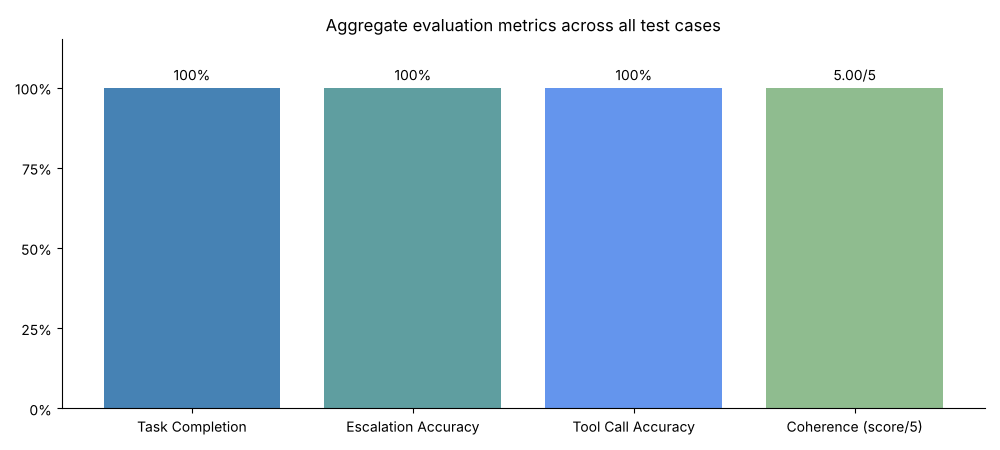

In [66]:
# ---- Aggregate the five metrics across all test cases ----
n_cases = len(all_results)

task_completion_rate = np.mean([r["task_completion"]["task_complete"] for r in all_results.values()])
exception_id_accuracy = np.mean([r["task_completion"]["exception_correct"] for r in all_results.values()])
resolution_accuracy = np.mean([r["task_completion"]["resolution_correct"] for r in all_results.values()])
tone_accuracy = np.mean([r["task_completion"]["tone_correct"] for r in all_results.values()])

esc_evaluated = [r["escalation_correct"] for r in all_results.values() if r["escalation_correct"] is not None]
escalation_accuracy = np.mean(esc_evaluated) if esc_evaluated else float("nan")

tool_call_accuracy = np.mean([r["tool_call_correct"] for r in all_results.values()])
coherence_scores = [r["coherence"]["score"] for r in all_results.values()]
mean_coherence = np.mean(coherence_scores)
latencies = [r["latency"] for r in all_results.values()]

total_llm_calls = sum(r["llm_usage"]["llm_calls"] for r in all_results.values())
total_tokens = sum(r["llm_usage"]["prompt_tokens"] + r["llm_usage"]["completion_tokens"] for r in all_results.values())
n_escalated = sum(1 for r in all_results.values() if r["state"].get("escalated"))
n_revisions = sum(r["state"].get("resolution_revision_count", 0) for r in all_results.values())

summary_df = pd.DataFrame([
    {"Metric": "Task Completion Rate",          "Value": f"{task_completion_rate:.0%}", "Detail": f"{int(task_completion_rate*n_cases)}/{n_cases} shipments fully correct (exception + resolution + tone)"},
    {"Metric": "  - Exception identification", "Value": f"{exception_id_accuracy:.0%}", "Detail": "is_exception matches ground truth"},
    {"Metric": "  - Resolution action",         "Value": f"{resolution_accuracy:.0%}", "Detail": "expected_resolution matches"},
    {"Metric": "  - Communication tone",        "Value": f"{tone_accuracy:.0%}", "Detail": "expected_tone matches (noise cases count as pass)"},
    {"Metric": "Escalation Accuracy",           "Value": f"{escalation_accuracy:.0%}", "Detail": f"{int(np.sum(esc_evaluated))}/{len(esc_evaluated)} exception cases; noise cases excluded"},
    {"Metric": "Tool Call Accuracy",            "Value": f"{tool_call_accuracy:.0%}", "Detail": "correct tool/agent set invoked for the path taken"},
    {"Metric": "Reasoning Trajectory Coherence","Value": f"{mean_coherence:.2f} / 5", "Detail": f"LLM-as-a-Judge ({EVAL_MODEL}); min {min(coherence_scores)}, max {max(coherence_scores)}"},
    {"Metric": "End-to-End Latency",            "Value": f"{np.mean(latencies):.2f}s mean", "Detail": f"median {np.median(latencies):.2f}s | max {max(latencies):.2f}s | total {sum(latencies):.1f}s"},
    {"Metric": "Escalations raised",            "Value": f"{n_escalated}/{n_cases}", "Detail": "shipments routed to a supervisor"},
    {"Metric": "Critic revision loops",         "Value": f"{n_revisions}", "Detail": "times the Critic sent a resolution back"},
    {"Metric": "LLM usage",                     "Value": f"{total_llm_calls} calls", "Detail": f"{total_tokens:,} tokens inside the pipeline (judge calls excluded)"},
])
print(f"AGGREGATE EVALUATION METRICS ({n_cases} test cases)\n")
display(summary_df.style.hide(axis="index"))

# ---- Chart: the four accuracy-style metrics plus normalised coherence ----
metric_names = ["Task Completion", "Escalation Accuracy", "Tool Call Accuracy", "Coherence (score/5)"]
metric_values = [task_completion_rate, escalation_accuracy, tool_call_accuracy, mean_coherence / 5]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(metric_names, metric_values, color=["#4682B4", "#5F9EA0", "#6495ED", "#8FBC8F"])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in metric_values[:3]] + [f"{mean_coherence:.2f}/5"], padding=3)
ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.set_title("Aggregate evaluation metrics across all test cases")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


We print the detailed per-shipment results showing ground truth versus predictions for each evaluation dimension, along with pass/fail status for task completion and tool calls, the coherence score, and latency.

This provides a complete at-a-glance view of where the system succeeded and where it diverged.

shipment,status,tier,GT exception,Pred exception,GT resolution,Pred resolution,GT escalate,Pred escalate,GT tone,Pred tone,Task,Escalation,Tools,Coherence,Latency (s),LLM calls,Revisions,Citations
SHP-001,DELIVERED,-,NO,NO,N/A,N/A,N/A,NO,N/A,N/A,PASS,N/A,PASS,5,0.000000,0,0,-
SHP-002,ATTEMPTED,VIP,YES,YES,RESCHEDULE,RESCHEDULE,YES,YES,FORMAL,FORMAL,PASS,PASS,PASS,5,13.580000,4,0,"p2, p3, p9, p1"
SHP-003,ADDRESS_ISSUE,STANDARD,YES,YES,RESCHEDULE,RESCHEDULE,NO,NO,CASUAL,CASUAL,PASS,PASS,PASS,5,10.590000,4,0,"p3, p2, p9"
SHP-004,DAMAGED,VIP,YES,YES,REPLACE,REPLACE,YES,YES,FORMAL,FORMAL,PASS,PASS,PASS,5,11.020000,4,0,"p4, p6, p9, p1"
SHP-005,ATTEMPTED,STANDARD,YES,YES,REROUTE_TO_LOCKER,REROUTE_TO_LOCKER,YES,YES,CASUAL,CASUAL,PASS,PASS,PASS,5,9.920000,4,0,"p2, p9"
SHP-006,REFUSED,STANDARD,YES,YES,RETURN_TO_SENDER,RETURN_TO_SENDER,NO,NO,CASUAL,CASUAL,PASS,PASS,PASS,5,7.990000,4,0,"p5, p2, p3, p9"
SHP-007,WEATHER_DELAY,VIP,YES,YES,REPLACE,REPLACE,YES,YES,FORMAL,FORMAL,PASS,PASS,PASS,5,11.960000,4,0,"p6, p9, p1"
SHP-008,ATTEMPTED,STANDARD,YES,YES,RESCHEDULE,RESCHEDULE,YES,YES,CASUAL,CASUAL,PASS,PASS,PASS,5,9.040000,4,0,"p2, p3, p9"
SHP-009,DAMAGED,PREMIUM,YES,YES,REPLACE,REPLACE,YES,YES,FORMAL,FORMAL,PASS,PASS,PASS,5,10.550000,4,0,"p4, p6, p9"
SHP-010,SCANNED,-,NO,NO,N/A,N/A,N/A,NO,N/A,N/A,PASS,N/A,PASS,5,0.000000,0,0,-


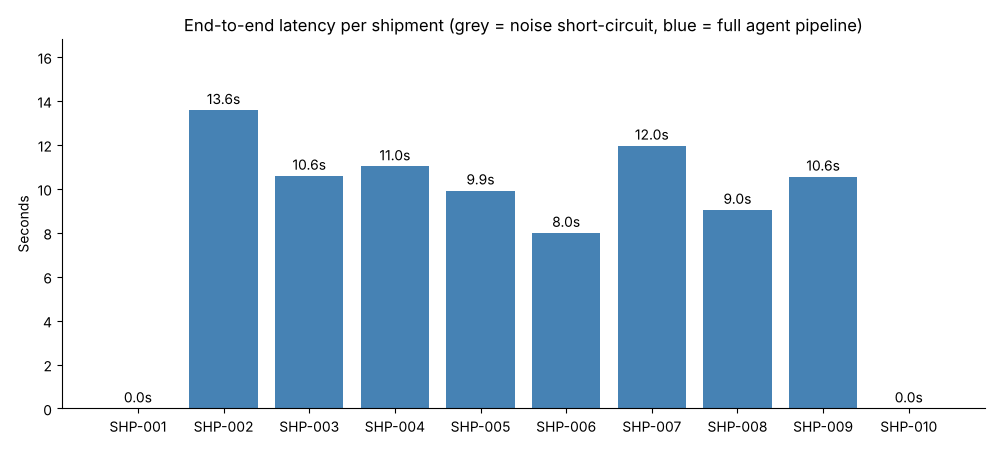

No divergence from ground truth on any dimension across all test cases.


In [67]:
# ---- Per-shipment results table: ground truth vs prediction on every dimension ----
rows = []
for sid, r in all_results.items():
    st = r["state"]
    gt = gt_consolidated[sid]
    res = st.get("resolution_output", {})
    rows.append({
        "shipment": sid,
        "status": st.get("consolidated_event", {}).get("status_code"),
        "tier": st.get("customer_profile", {}).get("tier", "-"),
        "GT exception": gt["is_exception"],
        "Pred exception": res.get("is_exception"),
        "GT resolution": gt["expected_resolution"],
        "Pred resolution": res.get("resolution"),
        "GT escalate": gt["should_escalate"],
        "Pred escalate": "YES" if st.get("escalated") else "NO",
        "GT tone": gt["expected_tone"],
        "Pred tone": st.get("communication_output", {}).get("tone_label", "N/A"),
        "Task": "PASS" if r["task_completion"]["task_complete"] else "FAIL",
        "Escalation": "N/A" if r["escalation_correct"] is None else ("PASS" if r["escalation_correct"] else "FAIL"),
        "Tools": "PASS" if r["tool_call_correct"] else "FAIL",
        "Coherence": r["coherence"]["score"],
        "Latency (s)": round(r["latency"], 2),
        "LLM calls": r["llm_usage"]["llm_calls"],
        "Revisions": st.get("resolution_revision_count", 0),
        "Citations": ", ".join(c.replace("Page ", "p") for c in r["citations"]) or "-",
    })
results_df = pd.DataFrame(rows)


def _color(v):
    return {"PASS": "background-color:#d9ead3", "FAIL": "background-color:#f4cccc"}.get(v, "")


display(results_df.style.map(_color, subset=["Task", "Escalation", "Tools"]).hide(axis="index"))

# ---- Chart: latency per shipment, coloured by path taken ----
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ["#A9A9A9" if all_results[s]["state"].get("noise_override") else "#4682B4" for s in results_df["shipment"]]
bars = ax.bar(results_df["shipment"], results_df["Latency (s)"], color=colors)
ax.bar_label(bars, labels=[f"{v:.1f}s" for v in results_df["Latency (s)"]], padding=2)
ax.set_title("End-to-end latency per shipment (grey = noise short-circuit, blue = full agent pipeline)")
ax.set_ylabel("Seconds")
ax.set_ylim(0, max(results_df["Latency (s)"]) * 1.2 + 0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# ---- Where did the system diverge from ground truth? ----
failures = results_df[(results_df["Task"] == "FAIL") | (results_df["Escalation"] == "FAIL") | (results_df["Tools"] == "FAIL")]
if failures.empty:
    print("No divergence from ground truth on any dimension across all test cases.")
else:
    print("Shipments with at least one failed dimension:")
    display(failures[["shipment", "GT resolution", "Pred resolution", "GT escalate", "Pred escalate", "GT tone", "Pred tone", "Task", "Escalation", "Tools"]])


Finally, we close the database connection.

In [68]:
db_conn.close()

# **Conclusions and Business Recommendations**

## Conclusions

The figures below are generated from the run above, so they always agree with the metrics tables.

In [69]:
print(f"Across {n_cases} curated shipments ({len(esc_evaluated)} real exceptions, {n_cases - len(esc_evaluated)} routine/noise shipments):")
print(f"  - Task completion rate ............ {task_completion_rate:.0%}")
print(f"  - Escalation accuracy ............. {escalation_accuracy:.0%}  ({n_escalated} escalations raised)")
print(f"  - Tool call accuracy .............. {tool_call_accuracy:.0%}")
print(f"  - Reasoning coherence (judge) ..... {mean_coherence:.2f} / 5")
print(f"  - Mean end-to-end latency ......... {np.mean(latencies):.2f}s per shipment (full pipeline cases: "
      f"{np.mean([r['latency'] for r in all_results.values() if not r['state'].get('noise_override')]):.2f}s; "
      f"noise cases: {np.mean([r['latency'] for r in all_results.values() if r['state'].get('noise_override')]):.3f}s)")
print(f"  - LLM calls inside the pipeline ... {total_llm_calls} ({total_tokens:,} tokens) - noise rows cost zero LLM calls")


Across 10 curated shipments (8 real exceptions, 2 routine/noise shipments):
  - Task completion rate ............ 100%
  - Escalation accuracy ............. 100%  (6 escalations raised)
  - Tool call accuracy .............. 100%
  - Reasoning coherence (judge) ..... 5.00 / 5
  - Mean end-to-end latency ......... 8.47s per shipment (full pipeline cases: 10.58s; noise cases: 0.001s)
  - LLM calls inside the pipeline ... 32 (56,948 tokens) - noise rows cost zero LLM calls


- **The hybrid design works: deterministic where policy is hard, LLM where judgment is needed.** De-duplication, consolidation, locker eligibility, the escalation rule engine and the noise filter are plain code, so they are exact and free; the LLM agents only handle the multi-factor calls (which action, how to word it) and are kept honest by Pydantic-validated schemas, a separate Critic model, and an orchestrator that enforces automatic escalations no matter what the LLM says. The per-shipment table above shows how each ground-truth dimension was met.
- **Noise never reaches an LLM.** Routine `DELIVERED` / `SCANNED` rows and duplicate scans are discarded by the preprocessor with zero tool or LLM calls, which is what makes the approach affordable at the volume of a real production event stream, where roughly 90% of rows are not exceptions (the curated test set is deliberately exception-heavy).
- **Escalation is precise in both directions.** Mandatory cases (3rd attempt, VIP with 3+ exceptions, damaged or weather-compromised perishables) are escalated by the rule engine; discretionary cases (a Standard customer with 6 exceptions) are escalated by the Critic's judgment; routine cases (first address problem, simple refusal) are *not* escalated, protecting supervisor capacity.
- **Every decision is auditable.** Each run produces the consolidated event, the tool calls made, the playbook pages retrieved (citations), the Resolution Agent's numbered rationale, both Critic verdicts, the customer message and the latency - the "document everything" ground rule of the playbook, satisfied automatically.
- **The hardest scenario exposes the real value.** SHP-005 (third attempt, only locker FULL) is exactly the kind of case a rigid rule engine gets wrong and a manual process handles slowly; here the system recommends the locker reroute *and* escalates with a concrete ask for the supervisor, which is what the playbook describes as good escalation communication.
- **Limitations.** The ground truth is a curated set of 10 shipments, so the metrics demonstrate correctness of the logic rather than statistical performance; LLM outputs are stabilised with `temperature=0` but are not guaranteed identical across runs; the coherence score is itself an LLM judgment and the judge can misread a legitimate escalation as an unresolved critique; retrieval relies on a small, well-structured playbook - a larger, messier manual would need chunking and query tuning; and the prompt-injection guardrail is implemented but not exercised by any of the ten curated cases, so its behaviour is untested here.

## Business Recommendations

1. **Pilot the system as a "recommend and draft" assistant, not a fully autonomous actor.** Let dispatchers approve the recommended action and the drafted message with one click for 4-6 weeks while the team measures agreement rate; auto-execute only the categories where agreement is consistently high (first-attempt reschedules, refusals, routine weather notices).
2. **Keep the rule engine as the system of record for policy.** Every automatic escalation trigger and every locker-eligibility rule lives in reviewable code, so Operations can change a threshold (e.g. the 4-hour perishable limit) without touching a prompt - and compliance can audit it.
3. **Invest in the playbook, because it is now executable.** The agents cite playbook pages, so gaps in the manual become visible as weak rationales. Add the missing policies the data exposes - what to do when no locker in the zip is eligible, adjacent-zip locker lists, temperature-controlled lockers - and the system improves without retraining.
4. **Measure the business KPIs the POC was built to move.** Track exception resolution time (target: minutes instead of the playbook's 30-minute resolution-path target), supervisor escalation precision, repeat-delivery truck rolls avoided via locker reroutes, spoilage write-offs prevented by pulling perishables early, and churn among customers with 2-3 failed deliveries. The latency and tool-call metrics above give the engineering baseline; these give the P&L story.
5. **Expand the exception taxonomy and the data feeds before multi-region rollout.** Add safety concerns, access-code issues and misroutes to the status codes, connect live scan feeds instead of a CSV, and add a `tone_preference` field to the customer profile (the playbook references it, the database does not yet have it).
6. **Close the loop on quality.** Log every supervisor override as a labelled example, re-run this evaluation harness nightly, and alert when task completion or escalation accuracy drifts - the five metrics in this notebook become the production monitoring dashboard.

**Expected benefits.** Resolution-path selection in seconds rather than tens of minutes; consistent, policy-cited decisions regardless of which dispatcher is on shift; proactive, tier-appropriate customer messages that reduce repeat-failure churn; fewer wasted truck rolls and perishable write-offs; and supervisors spending their time only on the cases that policy says need them.

<font size=6 color='#4682B4'>Power Ahead</font>
___